# Task 1: NLP Fundamentals, Pipeline & Data Exploration

**Objective:** Understand what NLP is, see where each pipeline stage appears in this project, and explore the airline tweet dataset.

**Expected output:** Written explanations, a loaded and de-duplicated dataset, three EDA plots and a table of five real tweets that show why NLP is hard.

## 1.1 What is NLP and why we need it

### What is Natural Language Processing (NLP)?

Natural Language Processing (NLP) is a branch of Artificial Intelligence (AI) that enables computers to understand, process, and generate human language. Human language is unstructured and contains grammar, slang, spelling mistakes, emojis, abbreviations, and different writing styles, making it difficult for computers to understand directly. NLP converts this text into a structured format so that machines can analyze and learn from it. It is widely used to extract useful information, classify text, translate languages, and answer user queries automatically. Today, NLP is an essential technology because millions of text messages, emails, reviews, and social media posts are generated every day.

### Real-Life Applications of NLP

1. **Search Engines (Google Search)** – understand what the user typed and rank the best pages.
2. **Spam Email Detection** – classify each email as spam or not spam.
3. **Chatbots and Virtual Assistants** – answer customer questions automatically.
4. **Machine Translation** – convert text from one language to another.
5. **Customer Review Sentiment Analysis** – find out whether customers are happy or unhappy (this project).

### Indian Use Cases

- **Google Translate** supports Indian languages such as Gujarati, Hindi, Tamil, and Bengali.
- **Aadhaar Virtual Assistant (Ask Aadhaar)** and many Indian banking chatbots use NLP to answer customer questions in multiple Indian languages.

## 1.2 Common NLP tasks and approaches

| NLP Task | Description | Example |
|-----------|-------------|----------|
| Text Classification | Assigns one label to a whole document | Marking an email as spam or not spam |
| Sentiment Analysis | Detects positive, negative, or neutral opinion | Labelling an airline tweet as negative |
| Named Entity Recognition (NER) | Finds names of people, places, and organizations | Tagging "Mumbai" and "Air India" in a news sentence |
| POS Tagging | Identifies the grammatical role of each word | "flight" → noun, "delayed" → verb |
| Machine Translation | Converts one language into another | English → Gujarati |
| Text Summarization | Generates a short summary of a long text | A 3-line summary of a news article |
| Question Answering | Answers a question written in natural language | "What time does my flight leave?" |

#### The three approach families used in this practical

| Approach | How it works | Used in this project | Needs labelled training data? |
|----------|--------------|----------------------|-------------------------------|
| Heuristic (rules) | Hand-written rules and word lists | Positive / negative word lists with a negation rule (Task 3.2) | No |
| API-based (ready-made service) | Send text to an existing engine and receive a sentiment score | NLTK VADER (Task 3.3); cloud APIs are only described | No (cloud APIs need an account and key) |
| Machine-Learning-based | Learn patterns from labelled examples | BoW / N-grams / TF-IDF / Word2Vec + classifier (Tasks 4–6) | Yes |

## 1.3 The NLP pipeline

```text
                    RAW TWEETS
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Data Collection            │
        │  Read Tweets.csv            │
        │  (Task 1.4)                 │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Text Cleaning              │
        │  • Remove URLs, @mentions   │
        │  • Keep hashtag word        │
        │  • Expand n't → not         │
        │  • Remove numbers/punct.    │
        │  • Lowercase                │
        │  (Task 2)                   │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Tokenization               │
        │  Split text into words      │
        │  (Task 2.4)                 │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Stopword Handling          │
        │  Remove stop-words but      │
        │  KEEP no / not / nor / never│
        │  (Task 2.4)                 │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Feature Extraction         │
        │  • Bag of Words             │
        │  • TF-IDF                   │
        │  • N-Grams                  │
        │  • Word2Vec                 │
        │  (Task 4 & 5)               │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Model Training             │
        │  • Logistic Regression      │
        │  • Naive Bayes / Linear SVM │
        │  (Task 6)                   │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Model Evaluation           │
        │  • Accuracy, Macro-F1       │
        │  • Precision / Recall       │
        │  • Confusion Matrix         │
        │  (Task 3.4 and Task 6)      │
        └─────────────────────────────┘
                        │
                        ▼
        ┌─────────────────────────────┐
        │  Deployment                 │
        │  Streamlit Web Application  │
        │  (Task 8)                   │
        └─────────────────────────────┘
```

## 1.4 Load and inspect

In [1]:
import os
import pandas as pd
import numpy as np

np.random.seed(42)                       # reproducibility
os.makedirs('screenshots', exist_ok=True)  # analysis plots are saved here for the GitHub repo

In [2]:
# Tweets.csv must be in the same folder as this notebook (download link is in the README)
df = pd.read_csv("Tweets.csv")

In [3]:
print("Dataset Shape :", df.shape)

Dataset Shape : (14640, 15)


In [4]:
df[['text','airline_sentiment','airline']].head()

,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America


In [5]:
print(df[['text','airline_sentiment','airline']].isnull().sum())

text                 0
airline_sentiment    0
airline              0
dtype: int64


In [6]:
duplicate_count = df['text'].duplicated().sum()

print("Duplicate Tweets :", duplicate_count)

Duplicate Tweets : 213


In [7]:
df = df.drop_duplicates(subset='text')

print("New Dataset Shape :", df.shape)

New Dataset Shape : (14427, 15)


In [8]:
for i, tweet in enumerate(df['text'].head(5), start=1):
    print("="*80)
    print(f"Tweet {i}")
    print(tweet)

Tweet 1
@VirginAmerica What @dhepburn said.
Tweet 2
@VirginAmerica plus you've added commercials to the experience... tacky.
Tweet 3
@VirginAmerica I didn't today... Must mean I need to take another trip!
Tweet 4
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse
Tweet 5
@VirginAmerica and it's a really big bad thing about it


In [9]:
print("="*50)
print("Dataset Summary")
print("="*50)

print("Rows :", df.shape[0])
print("Columns :", df.shape[1])
print("Unique Airlines :", df['airline'].nunique())
print("Sentiment Classes :", list(df['airline_sentiment'].unique()))

Dataset Summary
Rows : 14427
Columns : 15
Unique Airlines : 6
Sentiment Classes : ['neutral', 'positive', 'negative']


#### Conclusion
- The Twitter US Airline Sentiment dataset was successfully loaded (14,640 rows, 15 columns).
- None of the three columns we use (`text`, `airline_sentiment`, `airline`) has missing values.
- 213 duplicate tweets were found and removed, leaving 14,427 tweets.
- The dataset is now ready for Exploratory Data Analysis (EDA) and text preprocessing.

## 1.5 EDA plots

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# one fixed colour per class, reused in every chart of this notebook
colors = {'negative': '#d9534f', 'neutral': '#f0ad4e', 'positive': '#5cb85c'}

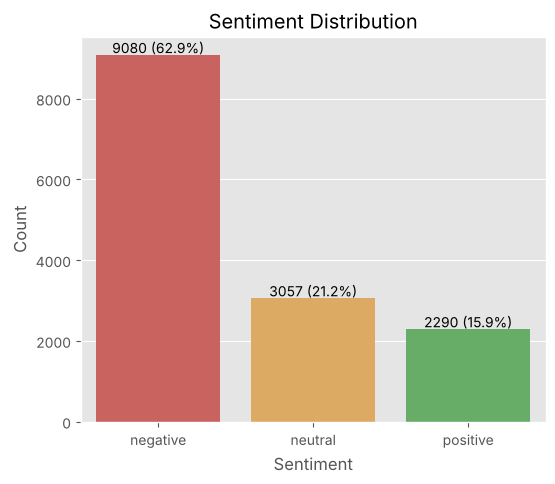

In [11]:
sentiment_counts = df['airline_sentiment'].value_counts()

plt.figure(figsize=(6,5))

ax = sns.countplot(
    x='airline_sentiment',
    data=df,
    order=sentiment_counts.index,
    hue='airline_sentiment',
    palette=colors,
    legend=False
)

total = len(df)

for p in ax.patches:
    percentage = 100*p.get_height()/total
    ax.annotate(f'{p.get_height():.0f} ({percentage:.1f}%)',
                (p.get_x()+p.get_width()/2, p.get_height()+50),
                ha='center')

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.savefig('screenshots/01_sentiment_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

- This graph shows the number and percentage of Positive, Neutral, and Negative tweets.

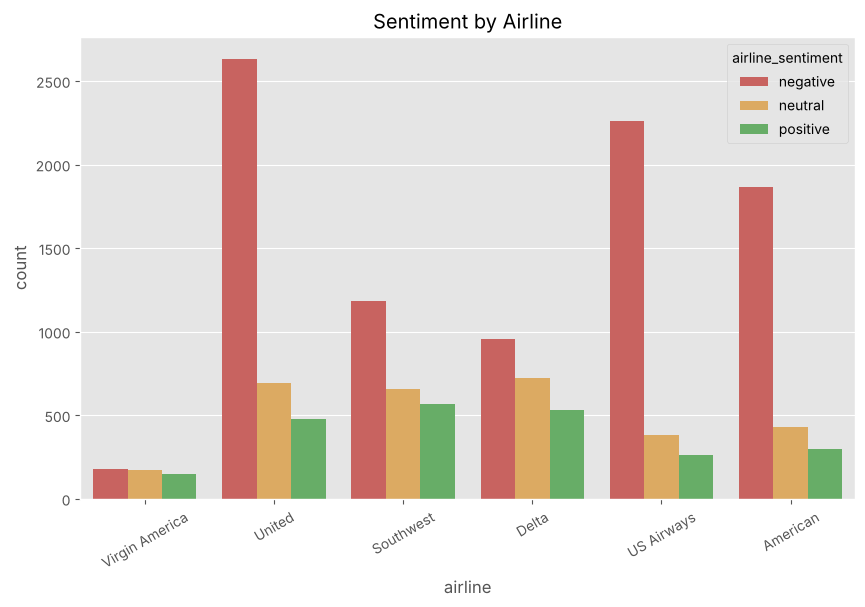

In [12]:
plt.figure(figsize=(10,6))

sns.countplot(
    x='airline',
    hue='airline_sentiment',
    hue_order=['negative','neutral','positive'],
    data=df,
    palette=colors
)

plt.title("Sentiment by Airline")
plt.xticks(rotation=30)
plt.savefig('screenshots/02_sentiment_by_airline.png', dpi=120, bbox_inches='tight')
plt.show()

- This graph compares customer sentiment across different airlines.

In [13]:
# share of negative tweets per airline (makes the chart above easier to read)
(pd.crosstab(df['airline'], df['airline_sentiment'], normalize='index')*100).round(1).sort_values('negative', ascending=False)

airline_sentiment,negative,neutral,positive
airline,,,
US Airways,77.8,13.1,9.1
American,71.9,16.6,11.5
United,69.2,18.2,12.6
Southwest,49.2,27.3,23.5
Delta,43.2,32.7,24.1
Virgin America,36.0,34.0,30.0


- The table gives the same chart in percentages: United, US Airways and American receive the largest share of negative tweets, while Virgin America and Delta receive the smallest.

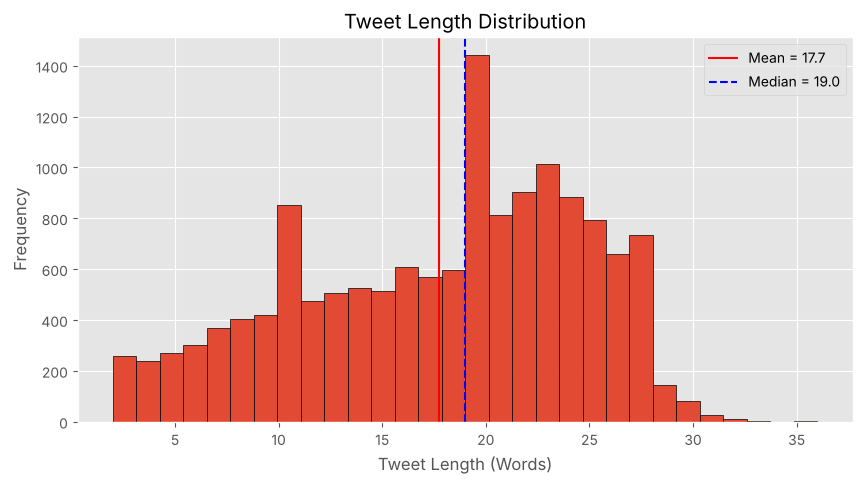

In [14]:
df['tweet_length'] = df['text'].apply(lambda x: len(x.split()))

mean_len = df['tweet_length'].mean()
median_len = df['tweet_length'].median()

plt.figure(figsize=(10,5))

plt.hist(df['tweet_length'],bins=30,edgecolor='black')

plt.axvline(mean_len,color='red',label=f'Mean = {mean_len:.1f}')

plt.axvline(median_len,color='blue',linestyle='--',label=f'Median = {median_len:.1f}')

plt.xlabel("Tweet Length (Words)")
plt.ylabel("Frequency")
plt.title("Tweet Length Distribution")

plt.legend()
plt.savefig('screenshots/03_tweet_length.png', dpi=120, bbox_inches='tight')
plt.show()

- The histogram shows the distribution of tweet lengths. The red line represents the mean, while the blue dashed line represents the median.

#### EDA Conclusion

- The dataset is **imbalanced**: about 63% of the tweets are negative, 21% neutral and only 16% positive.
- A model that always predicts "negative" would already reach about 63% accuracy without learning anything, so **accuracy alone is misleading**. **Macro F1-Score** (average F1 of the three classes) is used as the main metric because it gives the small neutral and positive classes the same weight as the big negative class.
- Some airlines receive a much larger share of negative feedback than others.
- Most tweets are short (a median of 19 words, mean about 18), so each tweet carries very little text for the model to learn from.

## 1.6 Challenges in NLP — evidence from real tweets

In [15]:
pd.set_option('display.max_colwidth', None)

def first_match(pattern, label=None):
    """Return the first tweet that matches a RegEx (word boundaries \b avoid accidental matches)."""
    mask = df['text'].str.contains(pattern, case=False, regex=True, na=False)
    if label is not None:
        mask &= (df['airline_sentiment'] == label)
    return df[mask].head(1)

# (a) Negation  - a positive word ("happy") flipped by "not"
negation  = first_match(r"\bnot happy\b", 'negative')

# (b) Sarcasm   - positive words with a negative meaning
sarcasm   = first_match(r"awesome service\.\.\. not", 'negative')

# (c) Slang / misspelling - "2" for "to" and "ur" for "your"
slang     = first_match(r"\b2 ur\b")

# (d) Emoji / special symbols
emoji     = first_match(r"❤")

# (e) Hard to label - the tweet with an annotator confidence below 0.5 that mixes praise and complaint
difficult = df[(df['airline_sentiment_confidence'] < 0.5) & df['text'].str.contains("commercials", case=False)].head(1)

- Each tweet is found with a RegEx / keyword search on the real dataset (nothing is invented). Word boundaries (`\b`) make sure that, for example, `not` does not match inside `nothing`.

In [16]:
examples = pd.concat([negation, sarcasm, slang, emoji, difficult])

examples['Challenge'] = ['Negation', 'Sarcasm', 'Slang / Misspelling', 'Emoji / Symbol', 'Hard to Label']

examples['Why it is hard for a computer'] = [
    "'happy' is a positive word, but 'not' reverses it. A model that only counts words sees 'happy' and may predict positive.",
    "'awesome service' looks very positive; only the final 'NOT' shows that the writer means the opposite.",
    "'2' stands for 'to' and 'ur' for 'your'. These are not normal dictionary words, and cleaning deletes the digit completely.",
    "All the positive feeling is inside the emoji (heart, smile, thumbs-up). Our RegEx removes them, so the cleaned tweet is only 'i flying'.",
    "'plus' sounds positive while 'tacky' is negative. The annotators were unsure (confidence about 0.35), so even a human cannot label it with certainty."
]

examples[['Challenge','text','airline_sentiment','airline_sentiment_confidence','Why it is hard for a computer']]

,Challenge,text,airline_sentiment,airline_sentiment_confidence,Why it is hard for a computer
1739,Negation,@united stuck in YYZ because staff took a break? Not happy 1K....,negative,1.0000,"'happy' is a positive word, but 'not' reverses it. A model that only counts words sees 'happy' and may predict positive."
1139,Sarcasm,@united been on the phone for over an hour with customer service and they can't figure it out! awesome service... NOT!,negative,1.0000,'awesome service' looks very positive; only the final 'NOT' shows that the writer means the opposite.
26,Slang / Misspelling,@VirginAmerica What happened 2 ur vegan food options?! At least say on ur site so i know I won't be able 2 eat anything for next 6 hrs #fail,negative,1.0000,"'2' stands for 'to' and 'ur' for 'your'. These are not normal dictionary words, and cleaning deletes the digit completely."
18,Emoji / Symbol,I ❤️ flying @VirginAmerica. ☺️👍,positive,1.0000,"All the positive feeling is inside the emoji (heart, smile, thumbs-up). Our RegEx removes them, so the cleaned tweet is only 'i flying'."
1,Hard to Label,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,0.3486,"'plus' sounds positive while 'tacky' is negative. The annotators were unsure (confidence about 0.35), so even a human cannot label it with certainty."


- Displays five real tweets from the dataset along with the NLP challenge they represent and a one-sentence explanation.

#### Conclusion

- Real-world tweets contain many language challenges such as negation, sarcasm, slang, emojis, and ambiguity.
- These challenges make preprocessing an essential step in any NLP pipeline, and they show why we later compare rules, a ready-made tool and a trained model.
- Proper text cleaning and feature extraction improve model performance.

# Task 2: Text Cleaning with RegEx & Tokenisation

**Objective:** Turn noisy raw tweets into clean text and tokens using RegEx, while keeping negation words that change sentiment.

**Expected output:** A tested `clean_text()` function, a `clean_text` column, tokens without stop-words (negations kept) and vocabulary statistics with plots.

## 2.1 Design the cleaning rules

## Text Cleaning Rules

| Cleaning Rule | Why It Is Used |
|---------------|----------------|
| Convert text to lowercase | Treat "Good" and "good" as the same word. |
| Decode HTML entities (`&amp;` → `&`) | The CSV contains `&amp;`, `&gt;` which would otherwise become the fake words "amp" and "gt". |
| Remove URLs | Website links do not contribute to sentiment analysis. |
| Remove @mentions | Every tweet starts with an airline name; it carries no sentiment. |
| Handle hashtags | Remove the '#' symbol but keep the word (e.g., #fail → fail). |
| **Expand negative contractions** (`didn't` → `did not`) | Removing punctuation would turn `didn't` into `didn t`, and the negation would be lost. About 13% of the tweets contain `n't`. |
| Remove numbers | Numbers usually do not express sentiment. |
| Remove punctuation | Remove unnecessary symbols such as .,!?;:'". |
| Remove extra whitespace | Makes the text clean and consistent. |

**Order matters:** lowercase first, then URLs and @mentions (they contain punctuation), then contractions (they contain an apostrophe), and only then numbers and punctuation.

### Note

Some cleaning rules may remove useful information.

- Exclamation marks (!) and ALL-CAPS may indicate strong emotions.
- Emojis can express positive or negative sentiment.
- Therefore, excessive cleaning should be avoided when sentiment information may be lost. (VADER in Task 3.3 is applied on the raw tweets for this reason.)

## 2.2 RegEx practice cells

In [17]:
import re

In [18]:
sample = "Visit https://www.google.com for more information."

result = re.sub(r'https?://\S+|www\.\S+', '', sample)

print("Original :", sample)
print("Cleaned  :", result)
print("Found    :", re.findall(r'https?://\S+|www\.\S+', sample))

Original : Visit https://www.google.com for more information.
Cleaned  : Visit  for more information.
Found    : ['https://www.google.com']


- Removes website links from the text (`re.findall` shows what was matched).

In [19]:
sample = "@united Thanks for your support. cc @delta"

result = re.sub(r'@\w+', '', sample)

print("Original :", sample)
print("Cleaned  :", result)
print("Found    :", re.findall(r'@\w+', sample))

Original : @united Thanks for your support. cc @delta
Cleaned  :  Thanks for your support. cc 
Found    : ['@united', '@delta']


- Removes Twitter usernames beginning with @.

In [20]:
sample = "I love #Python and #MachineLearning"

result = re.sub(r'#(\w+)', r'\1', sample)

print("Original :", sample)
print("Cleaned  :", result)
print("Found    :", re.findall(r'#(\w+)', sample))

Original : I love #Python and #MachineLearning
Cleaned  : I love Python and MachineLearning
Found    : ['Python', 'MachineLearning']


- Removes only the # symbol while keeping the hashtag word (`\1` means "the text captured inside the brackets").

In [21]:
sample = "I bought 3 tickets for 2500 rupees."

result = re.sub(r'\d+', '', sample)

print("Original :", sample)
print("Cleaned  :", result)
print("Found    :", re.findall(r'\d+', sample))

Original : I bought 3 tickets for 2500 rupees.
Cleaned  : I bought  tickets for  rupees.
Found    : ['3', '2500']


- Removes all numeric values from the text.

In [22]:
sample = "hello!!! how are you?? :) 😡"

result = re.sub(r'[^a-z\s]', '', sample)

print("Original :", sample)
print("Cleaned  :", result)

Original : hello!!! how are you?? :) 😡
Cleaned  : hello how are you  


- Removes punctuation, digits, emoji and special symbols while keeping lowercase letters and spaces (this rule runs after lower-casing).

In [23]:
sample = "Python      is      awesome"

result = re.sub(r'\s+', ' ', sample).strip()

print("Original :", sample)
print("Cleaned  :", result)

Original : Python      is      awesome
Cleaned  : Python is awesome


- Replaces multiple spaces with a single space and removes leading/trailing spaces.

In [24]:
# The negation trap: removing punctuation WITHOUT expanding the contraction loses the word "not"
sample = "i didn't like it and i can't wait to leave"

wrong = re.sub(r'[^a-z\s]', ' ', sample)
print("Punctuation removed only :", wrong)

right = re.sub(r"\bcan't\b", "can not", sample)
right = re.sub(r"n't\b", " not", right)
print("Contraction expanded     :", right)

Punctuation removed only : i didn t like it and i can t wait to leave
Contraction expanded     : i did not like it and i can not wait to leave


- Without the contraction rule, `didn't` becomes `didn t` and the negation disappears. This is why the rule is part of `clean_text()`.

#### Common RegEx Patterns

| Pattern | Meaning of each symbol | Example match |
|----------|---------|---------|
| `https?://\S+` | `http` literal, `s?` = optional "s", `://` literal, `\S+` = one or more non-space characters | https://t.co/abc123 |
| `@\w+` | `@` literal, `\w+` = one or more letters, digits or underscore | @united |
| `#(\w+)` | `#` literal, `( )` = capture group, `\1` in the replacement = the captured word | #fail → fail |
| `\d+` | `\d` = any digit, `+` = one or more | 2500 |
| `[^a-z\s]` | `[ ]` = character set, `^` = NOT, `a-z` = lowercase letters, `\s` = whitespace | `!`, `?`, `😡`, `-` |
| `\s+` | `\s` = any whitespace, `+` = one or more | "Hello     World" |
| `n't\b` | `n't` literal, `\b` = word boundary | didn't → did not |

## 2.3 clean_text() function

In [25]:
import html

def clean_text(text):

    # Convert to lowercase
    text = str(text).lower()

    # Decode HTML entities (&amp; -> &) and normalise curly apostrophes
    text = html.unescape(text)
    text = text.replace("’", "'").replace("‘", "'")

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove @mentions
    text = re.sub(r'@\w+', ' ', text)

    # Remove hashtag symbol but keep the word
    text = re.sub(r'#(\w+)', r'\1', text)

    # Expand negative contractions so the negation survives punctuation removal
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bcannot\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)

    # Remove other contractions ('s, 'll, 're, 've, 'd, 'm)
    text = re.sub(r"'(?:s|ll|re|ve|d|m)\b", "", text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation, emoji and symbols
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [26]:
df['clean_text'] = df['text'].apply(clean_text)

df[['text','clean_text']].head()

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you added commercials to the experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,i did not today must mean i need to take another trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",it really aggressive to blast obnoxious entertainment in your guests faces they have little recourse
4,@VirginAmerica and it's a really big bad thing about it,and it a really big bad thing about it


In [27]:
# 5 raw tweets and their cleaned version side by side
comparison = df[['text','clean_text']].head(5)

comparison

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus you added commercials to the experience tacky
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,i did not today must mean i need to take another trip
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",it really aggressive to blast obnoxious entertainment in your guests faces they have little recourse
4,@VirginAmerica and it's a really big bad thing about it,and it a really big bad thing about it


In [28]:
# Check the negation fix on real tweets that contain n't
check = df[df['text'].str.contains("n't")][['text','clean_text']].head(3)

check

,text,clean_text
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,i did not today must mean i need to take another trip
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,seriously would pay a flight for seats that did not have this playing it really the only bad thing about flying va
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i did not but now i do d


In [29]:
empty_tweets = (df['clean_text'].str.strip() == '').sum()

print("Empty Tweets After Cleaning :", empty_tweets)

Empty Tweets After Cleaning : 0


In [30]:
# Safety step: drop tweets that would become empty (0 in this dataset, but the rule keeps the pipeline robust)
df = df[df['clean_text'].str.strip() != '']

print("Dataset Shape :", df.shape)

Dataset Shape : (14427, 17)


- The `clean_text()` function removes unwanted information while preserving meaningful words (including negations such as `did not`). The cleaned text is stored in a new column; the raw `text` column stays untouched.
- No tweet became empty in this dataset because every tweet contains at least one letter-word. Empty results are still dropped here, and the Streamlit app (Task 8) shows a warning when a user types only emojis or a URL.

## 2.4 Tokenisation and stop-words

In [31]:
import nltk

_ = nltk.download('punkt', quiet=True)
_ = nltk.download('punkt_tab', quiet=True)   # newer NLTK versions need this name
_ = nltk.download('stopwords', quiet=True)

In [32]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

In [33]:
# Create Stop-word List
all_stop_words = set(stopwords.words('english'))

# Keep negation words (remove them from the stop-word set)
keep_words = {'no', 'not', 'nor', 'never'}

stop_words = all_stop_words - keep_words

print("Total Stopwords (NLTK)       :", len(all_stop_words))
print("Total Stopwords (negations kept) :", len(stop_words))

Total Stopwords (NLTK)       : 198
Total Stopwords (negations kept) : 195


In [34]:
# Tokenization
df['tokens'] = df['clean_text'].apply(word_tokenize)

df[['clean_text','tokens']].head()

,clean_text,tokens
0,what said,"[what, said]"
1,plus you added commercials to the experience tacky,"[plus, you, added, commercials, to, the, experience, tacky]"
2,i did not today must mean i need to take another trip,"[i, did, not, today, must, mean, i, need, to, take, another, trip]"
3,it really aggressive to blast obnoxious entertainment in your guests faces they have little recourse,"[it, really, aggressive, to, blast, obnoxious, entertainment, in, your, guests, faces, they, have, little, recourse]"
4,and it a really big bad thing about it,"[and, it, a, really, big, bad, thing, about, it]"


In [35]:
# Remove Stop Words (negations are kept)
df['filtered_tokens'] = df['tokens'].apply(
    lambda words: [word for word in words if word not in stop_words]
)

df[['tokens','filtered_tokens']].head()

,tokens,filtered_tokens
0,"[what, said]",[said]
1,"[plus, you, added, commercials, to, the, experience, tacky]","[plus, added, commercials, experience, tacky]"
2,"[i, did, not, today, must, mean, i, need, to, take, another, trip]","[not, today, must, mean, need, take, another, trip]"
3,"[it, really, aggressive, to, blast, obnoxious, entertainment, in, your, guests, faces, they, have, little, recourse]","[really, aggressive, blast, obnoxious, entertainment, guests, faces, little, recourse]"
4,"[and, it, a, really, big, bad, thing, about, it]","[really, big, bad, thing]"


In [36]:
# Example of Negation
sentence = "I am not happy with the delay"

tokens = word_tokenize(sentence.lower())

blind    = [word for word in tokens if word not in all_stop_words]   # removes "not" too
careful  = [word for word in tokens if word not in stop_words]       # keeps "not"

print("Original Sentence      :", sentence)
print("Tokens                 :", tokens)
print("\nBlind stop-word removal  :", blind)
print("Negation words kept      :", careful)

Original Sentence      : I am not happy with the delay
Tokens                 : ['i', 'am', 'not', 'happy', 'with', 'the', 'delay']

Blind stop-word removal  : ['happy', 'delay']
Negation words kept      : ['not', 'happy', 'delay']


### Why Keep Negation Words?

If we remove **not**, **no**, or **nor**, the meaning of a sentence may completely change.

Example:

Original:
> I am **not** happy with the delay.

After blind stop-word removal:
> ['happy', 'delay']

A model now sees "happy" and may predict a positive tweet, although the customer is angry. Keeping `not` gives `['not', 'happy', 'delay']`, so the sentiment is preserved.

### Conclusion

Tokenization converts sentences into individual words. Stop-word removal reduces unnecessary words while preserving negation words, ensuring that the original sentiment of the text is maintained.

## 2.5 Vocabulary statistics

In [37]:
from collections import Counter

In [38]:
# Vocabulary Size Before Cleaning

original_vocab = set()

for text in df['text']:
    words = str(text).lower().split()
    original_vocab.update(words)

print("Vocabulary Size Before Cleaning :", len(original_vocab))

Vocabulary Size Before Cleaning : 26840


- Counts all unique words in the original tweets (split on spaces, so `delayed.` and `delayed` count as different words).

In [39]:
# Vocabulary Size After Cleaning
clean_vocab = set()

for text in df['clean_text']:
    words = text.split()
    clean_vocab.update(words)

print("Vocabulary Size After Cleaning :", len(clean_vocab))

Vocabulary Size After Cleaning : 11162


- Counts the number of unique words after preprocessing.

In [40]:
# Top 20 Most Frequent Words (after stop-word removal, negations kept)
all_words = [w for tokens in df['filtered_tokens'] for w in tokens]

word_counts = Counter(all_words)

top20 = word_counts.most_common(20)

top20_df = pd.DataFrame(top20, columns=['Word','Frequency'])

top20_df

,Word,Frequency
0,flight,3905
1,not,3723
2,no,1484
3,get,1333
4,cancelled,1043
5,thanks,1041
6,service,959
7,help,864
8,time,786
9,customer,750


- Displays the 20 most frequently occurring words in the cleaned dataset (stop-words removed, so the list shows meaningful words).

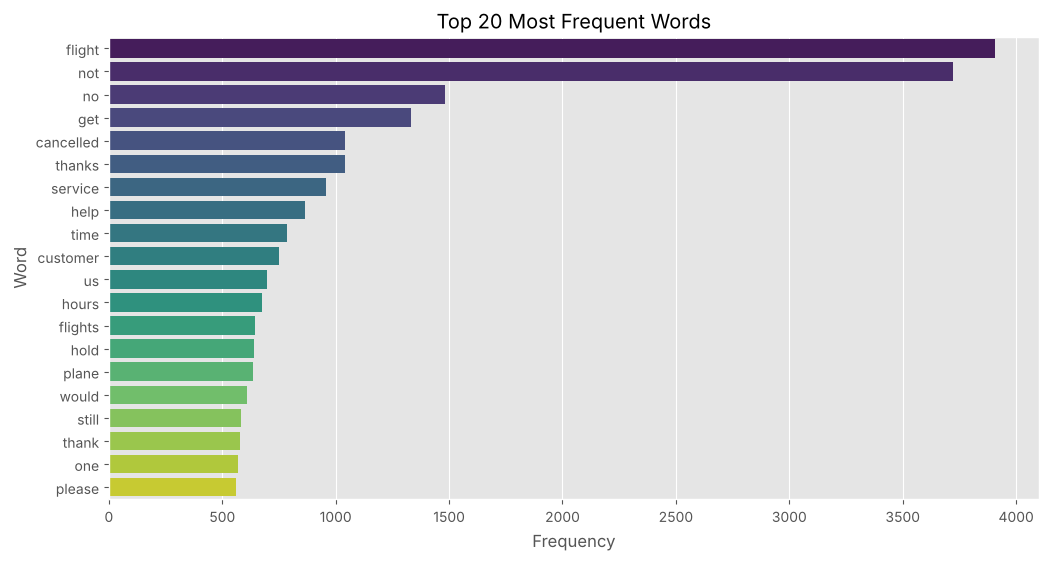

In [41]:
# Plot Top 20 Words

plt.figure(figsize=(12,6))

sns.barplot(
    data=top20_df,
    x='Frequency',
    y='Word',
    hue='Word',
    palette='viridis',
    legend=False
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

- Visualizes the most common words after text preprocessing.

In [42]:
# Words Appearing Only Once
rare_words = sum(1 for word,count in word_counts.items() if count==1)

print("Unique words (after stop-word removal) :", len(word_counts))
print("Words Appearing Only Once              :", rare_words)
print(f"Share of the vocabulary                : {100*rare_words/len(word_counts):.1f}%")

Unique words (after stop-word removal) : 11030
Words Appearing Only Once              : 5508
Share of the vocabulary                : 49.9%


- Counts rare words that appear only one time in the dataset.

In [43]:
# Top 20 tokens for EACH sentiment class (side by side)
class_counters = {}

for label in ['negative','neutral','positive']:
    tokens = [w for toks in df[df['airline_sentiment']==label]['filtered_tokens'] for w in toks]
    class_counters[label] = Counter(tokens)

top20_by_class = pd.DataFrame({
    label: [f"{w} ({c})" for w, c in class_counters[label].most_common(20)]
    for label in class_counters
})
top20_by_class.index = range(1, 21)

top20_by_class

,negative,neutral,positive
1,not (3169),flight (606),thanks (579)
2,flight (2919),not (358),thank (431)
3,no (1305),get (235),flight (380)
4,get (985),please (180),great (234)
5,cancelled (907),flights (169),not (196)
6,service (744),help (168),service (160)
7,hours (651),need (162),love (134)
8,help (612),thanks (152),customer (113)
9,hold (608),dm (131),get (113)
10,customer (607),would (128),guys (108)


- Shows the 20 most frequent tokens of every sentiment class, with their counts in brackets.

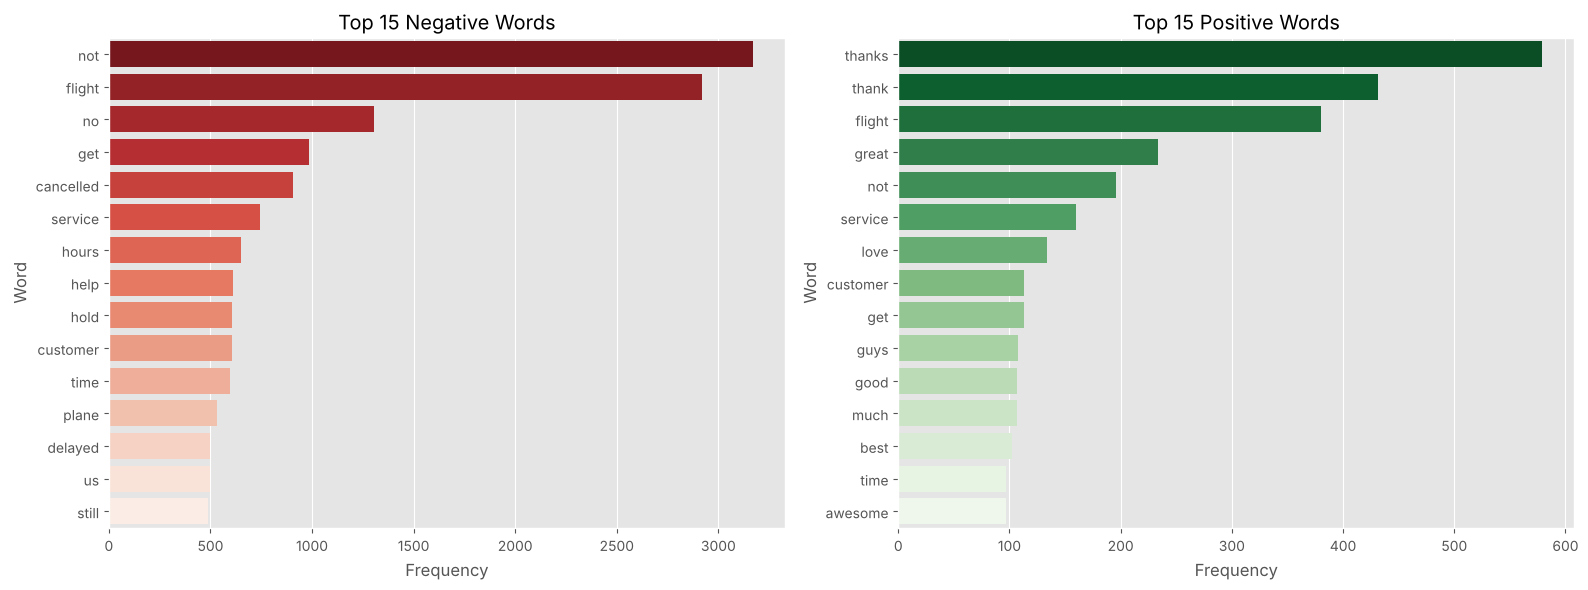

In [44]:
# Top 15 words of the negative and positive classes
negative_df = pd.DataFrame(class_counters['negative'].most_common(15), columns=['Word','Frequency'])
positive_df = pd.DataFrame(class_counters['positive'].most_common(15), columns=['Word','Frequency'])

# Plot Side-by-Side Charts
fig, axes = plt.subplots(1, 2, figsize=(16,6))

# Negative
sns.barplot(data=negative_df, x='Frequency', y='Word', hue='Word', palette='Reds_r', legend=False, ax=axes[0])
axes[0].set_title("Top 15 Negative Words")

# Positive
sns.barplot(data=positive_df, x='Frequency', y='Word', hue='Word', palette='Greens_r', legend=False, ax=axes[1])
axes[1].set_title("Top 15 Positive Words")

plt.tight_layout()
plt.savefig('screenshots/04_top_words_by_class.png', dpi=120, bbox_inches='tight')
plt.show()

- Compares the most frequent words used in negative and positive tweets.

In [45]:
# How many words would survive different min_df values?
for k in [1, 2, 3, 5]:
    kept = sum(1 for c in word_counts.values() if c >= k)
    covered = sum(c for c in word_counts.values() if c >= k) / sum(word_counts.values())
    print(f"min_df-style cut-off {k}: {kept:6d} words kept ({100*kept/len(word_counts):5.1f}% of vocabulary) -> cover {100*covered:5.1f}% of all word occurrences")

min_df-style cut-off 1:  11030 words kept (100.0% of vocabulary) -> cover 100.0% of all word occurrences
min_df-style cut-off 2:   5522 words kept ( 50.1% of vocabulary) -> cover  95.8% of all word occurrences
min_df-style cut-off 3:   4069 words kept ( 36.9% of vocabulary) -> cover  93.5% of all word occurrences
min_df-style cut-off 5:   2775 words kept ( 25.2% of vocabulary) -> cover  90.2% of all word occurrences


### Vocabulary Analysis

#### Observations

- The vocabulary shrinks from 26,840 to 11,162 words after cleaning, because URLs, @mentions, punctuation and numbers no longer create separate words (`delayed.`, `delayed!` and `delayed` all become `delayed`).
- About half of the vocabulary appears only once (typos, usernames, flight numbers). These words are noise for a model.
- **Surprising words:**
  - `not` and `no` are among the top words of the **negative** class, so negation is a strong signal and stop-word removal must not delete it.
  - `thanks` is the number one word of the positive class, but it also appears about 300 times in negative tweets ("thanks for nothing"), so one word can point to both classes.
  - `fleek`, `fleet` and `destinationdragons` are top **neutral** words, because Virgin America ran a "fleet on fleek" promotion that many users retweeted. This is a dataset quirk.
  - `cancelled` and `flightled` (from the phrase "Cancelled Flightled") are typical airline complaint words that general-purpose tools do not know.
- Negative tweets are dominated by delay, cancellation, waiting and customer-service words; positive tweets by thanks, great, love, awesome, best.

#### What this means for Task 4

- **`min_df = 2`** removes the words that appear only once (about half of the vocabulary) but still covers about 96% of all word occurrences (only about 4% are lost), so it is a safe setting.
- **`max_features = 5000`** keeps the frequent words that cover almost all of the text, while making the matrix smaller and faster. A larger value mostly adds rare words.

# Task 3: Different NLP Approaches — Heuristic & API-based

**Objective:** Build a rule-based sentiment classifier and a VADER-based classifier, and measure both on the same test set.

**Expected output:** A 30-40 word airline lexicon with negation handling, VADER predictions, a metrics table with confusion matrices and four explained failure cases.

## 3.1 Approaches overview

### 1. Heuristic (Rule-Based) Approach

The heuristic approach uses manually created rules and predefined positive and negative word lists to determine sentiment. It does not require training data and is easy to understand. However, it struggles with sarcasm, complex language, and context.

#### Advantages
- Simple to implement
- No training required
- Fast execution and fully explainable

#### Disadvantages
- Low accuracy for complex sentences
- Cannot understand context or sarcasm
- Requires manual maintenance of the word lists

---

### 2. API-Based Approach

API-based sentiment analysis sends text to a ready-made engine (a cloud service, or a pre-built library such as VADER or TextBlob) and receives a sentiment score. These tools are already built and can directly predict sentiment without building a model.

#### Advantages
- Easy to use
- Reasonable accuracy on general text
- No model training required

#### Disadvantages
- Limited customization (it does not know airline words)
- Cloud APIs need an account, internet, an API key and billing
- Private text leaves the company when a cloud service is used

---

### 3. Machine Learning Approach

Machine Learning learns patterns from labeled data using algorithms such as Logistic Regression or Naive Bayes with features like BoW, TF-IDF, and Word2Vec.

#### Advantages
- Learns the vocabulary of the domain
- Usually the highest accuracy when enough data is available
- Data stays inside the company

#### Disadvantages
- Requires labeled data
- Training and re-training take time
- More computational resources needed

### When to Use Each Approach

| Situation | Best Approach | Reason |
|-----------|---------------|--------|
| Small project with limited budget and no labelled data | Heuristic | Simple and free |
| Quick sentiment analysis of general text, no time to build | API-Based | Ready-to-use solution |
| Company with enough labelled data and a specific domain | Machine Learning | Learns domain words, higher accuracy |
| Privacy-sensitive applications | Heuristic or Machine Learning (local) | Data never leaves the company |

## 3.2 Heuristic approach

In [46]:
# Airline-specific sentiment lexicon, chosen after studying the frequent words of each class in Task 2.5
positive_words = {
    "thanks", "thank", "thx", "great", "love", "loved", "good", "best",
    "awesome", "amazing", "appreciate", "appreciated", "helpful", "nice",
    "excellent", "fantastic", "wonderful", "perfect", "friendly", "kind",
    "smooth", "comfortable", "easy", "happy", "glad", "enjoy", "enjoyed",
    "impressed", "outstanding", "superb", "professional", "pleasant",
    "brilliant", "favorite", "fabulous", "grateful"
}

negative_words = {
    "cancelled", "canceled", "cancel", "flightled", "delayed", "delay",
    "delays", "late", "lost", "worst", "rude", "terrible", "awful",
    "horrible", "bad", "worse", "hate", "hold", "waiting", "stuck",
    "broken", "disappointed", "disappointing", "unacceptable", "ridiculous",
    "mess", "nightmare", "fail", "failed", "refund", "missed", "damaged",
    "stranded", "unhappy", "angry", "frustrated", "frustrating", "useless",
    "hours", "hrs"
}

print("Positive words :", len(positive_words))
print("Negative words :", len(negative_words))

Positive words : 36
Negative words : 40


- Two word lists with 36 positive and 40 negative words. Many words are airline-specific (`cancelled`, `flightled`, `delay`, `hold`, `hours`, `lost`, `rude`) and include spelling variants seen in tweets (`thx`, `canceled`, `hrs`).
- Words were kept or removed after checking the score on the **training** tweets only, never the test tweets. For example, removing `hold` or `hours` lowered the training score, so they stay.

In [47]:
negation_words = {"not", "no", "never"}

- These words reverse the meaning of a sentiment word that follows them within two positions ("not very helpful").

In [48]:
# Create Heuristic Function
def heuristic_score(text):

    words = clean_text(text).split()

    score = 0

    for i, word in enumerate(words):

        if word in positive_words:
            polarity = 1
        elif word in negative_words:
            polarity = -1
        else:
            continue

        # flip the polarity if one of the previous two words is a negation
        if any(w in negation_words for w in words[max(0, i-2):i]):
            polarity = -polarity

        score += polarity

    return score


def heuristic_sentiment(text):

    score = heuristic_score(text)

    if score > 0:
        return "positive"

    elif score < 0:
        return "negative"

    else:
        return "neutral"

- The function cleans the tweet, counts positive and negative words, and reverses the polarity if a negation word appears in the previous two words. It returns **lower-case** labels (`positive`, `negative`, `neutral`) so that they match the dataset labels exactly. Neutral is returned when the score is 0 or no word matches.

In [49]:
# Test on Five Hand-Picked Tweets
hand_picked = [
    "@united thanks for the great service, the crew was awesome!",
    "@delta my flight was cancelled and delayed, worst airline ever",
    "@jetblue I am not happy with the delay",
    "@SouthwestAir what is the baggage allowance for international flights?",
    "@AmericanAir no delay today, thank you!"
]

test_table = pd.DataFrame({
    'Tweet': hand_picked,
    'Score': [heuristic_score(t) for t in hand_picked],
    'Predicted Sentiment': [heuristic_sentiment(t) for t in hand_picked]
})

test_table

,Tweet,Score,Predicted Sentiment
0,"@united thanks for the great service, the crew was awesome!",3,positive
1,"@delta my flight was cancelled and delayed, worst airline ever",-3,negative
2,@jetblue I am not happy with the delay,-2,negative
3,@SouthwestAir what is the baggage allowance for international flights?,0,neutral
4,"@AmericanAir no delay today, thank you!",2,positive


- Shows the score for five tweets I wrote myself: a positive one, a negative one, a negation ("not happy" is reversed to negative), a neutral question (no lexicon word) and "no delay" (the negation reverses `delay` to positive).

In [50]:
# Compare with actual labels on 5 real tweets
comparison = df[['text','airline_sentiment']].head(5).copy()

comparison['Predicted'] = comparison['text'].apply(heuristic_sentiment)

comparison

,text,airline_sentiment,Predicted
0,@VirginAmerica What @dhepburn said.,neutral,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,neutral
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative,neutral
4,@VirginAmerica and it's a really big bad thing about it,negative,negative


- Compares the heuristic predictions with the actual sentiment labels for the first five real tweets.

### Conclusion

The heuristic approach is simple and does not require model training. It works for tweets that contain a word from the list, but it struggles with sarcasm, context, and words that are not in the lexicon. This limitation motivates the use of API-based and Machine Learning approaches in later tasks.

## 3.3 API-based approach

In [51]:
_ = nltk.download('vader_lexicon', quiet=True)

- Downloads the VADER sentiment dictionary used for sentiment prediction.

In [52]:
from nltk.sentiment import SentimentIntensityAnalyzer

In [53]:
sia = SentimentIntensityAnalyzer()

In [54]:
# Check Sentiment Score
sample = "The flight was delayed but the staff was very helpful."

score = sia.polarity_scores(sample)

print(score)

{'neg': 0.107, 'neu': 0.589, 'pos': 0.305, 'compound': 0.5704}


Returns four scores:
- `neg`, `neu`, `pos` – the share of negative, neutral and positive text
- `compound` – the overall sentiment from -1 (very negative) to +1 (very positive)

In [55]:
# Create Prediction Function
def vader_sentiment(text):

    score = sia.polarity_scores(text)['compound']

    if score >= 0.05:
        return "positive"

    elif score <= -0.05:
        return "negative"

    else:
        return "neutral"

Uses the compound score to classify sentiment:
- ≥ 0.05 → Positive
- ≤ -0.05 → Negative
- Otherwise → Neutral

In [56]:
# Apply VADER on the RAW tweets (VADER is designed for social media: it understands ALL-CAPS, "!!!" and :) )
df['vader_prediction'] = df['text'].apply(vader_sentiment)

df[['text','airline_sentiment','vader_prediction']].head()

,text,airline_sentiment,vader_prediction
0,@VirginAmerica What @dhepburn said.,neutral,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,neutral
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative,negative
4,@VirginAmerica and it's a really big bad thing about it,negative,negative


- Predicts sentiment for every tweet using VADER.

In [57]:
# Display Sentiment Scores
scores = df['text'].head(5).apply(sia.polarity_scores)

scores

0            {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
1            {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
2            {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}
3    {'neg': 0.246, 'neu': 0.754, 'pos': 0.0, 'compound': -0.5984}
4    {'neg': 0.321, 'neu': 0.679, 'pos': 0.0, 'compound': -0.5829}
Name: text, dtype: object

- Displays detailed VADER scores for five tweets.

### Cloud NLP APIs

Popular cloud sentiment analysis services include:

- Google Cloud Natural Language API
- AWS Comprehend
- Azure Text Analytics

These services work the same way as VADER from the outside: you send text through an API and the service returns a JSON result with a sentiment score. They need an account, an API key and billing (usage charges), and the text is sent to the provider's servers. For these reasons they are only **described** here and not used.

VADER is not literally a web service; it is a ready-made lexicon-and-rules engine that runs locally. We use it as the "API-based" example because we also just pass in text and get a score back without any training.

## 3.4 Evaluate both on the same test set

In [58]:
from sklearn.model_selection import train_test_split

X = df['text']
y = df['airline_sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# cleaned versions of the same tweets (same split!) for the ML models of later tasks
X_train_clean = df.loc[X_train.index, 'clean_text']
X_test_clean  = df.loc[X_test.index,  'clean_text']

print("Train tweets :", len(X_train))
print("Test tweets  :", len(X_test))

Train tweets : 11541
Test tweets  : 2886


- Splits the dataset into 80% training and 20% testing while preserving class distribution. This split is done **before** any vectoriser or Word2Vec model is fitted, so the test tweets stay unseen.

In [59]:
heuristic_predictions = X_test.apply(heuristic_sentiment)
vader_predictions     = X_test.apply(vader_sentiment)

In [60]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

labels = ['negative', 'neutral', 'positive']

def evaluate(name, y_true, y_pred):
    """Return accuracy, macro-F1 and per-class precision / recall as one table row."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {
        'Approach': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro-F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Precision (neg)': p[0], 'Precision (neu)': p[1], 'Precision (pos)': p[2],
        'Recall (neg)': r[0],    'Recall (neu)': r[1],    'Recall (pos)': r[2],
    }

In [61]:
approach_results = pd.DataFrame([
    evaluate('Heuristic (own lexicon)', y_test, heuristic_predictions),
    evaluate('API-based (VADER)',       y_test, vader_predictions),
]).set_index('Approach').round(3)

approach_results

,Accuracy,Macro-F1,Precision (neg),Precision (neu),Precision (pos),Recall (neg),Recall (neu),Recall (pos)
Approach,,,,,,,,
Heuristic (own lexicon),0.559,0.572,0.921,0.323,0.612,0.449,0.779,0.703
API-based (VADER),0.549,0.515,0.900,0.387,0.339,0.506,0.426,0.882


- Accuracy, macro-F1 and per-class precision / recall of both approaches on the **same 2,886 test tweets**.

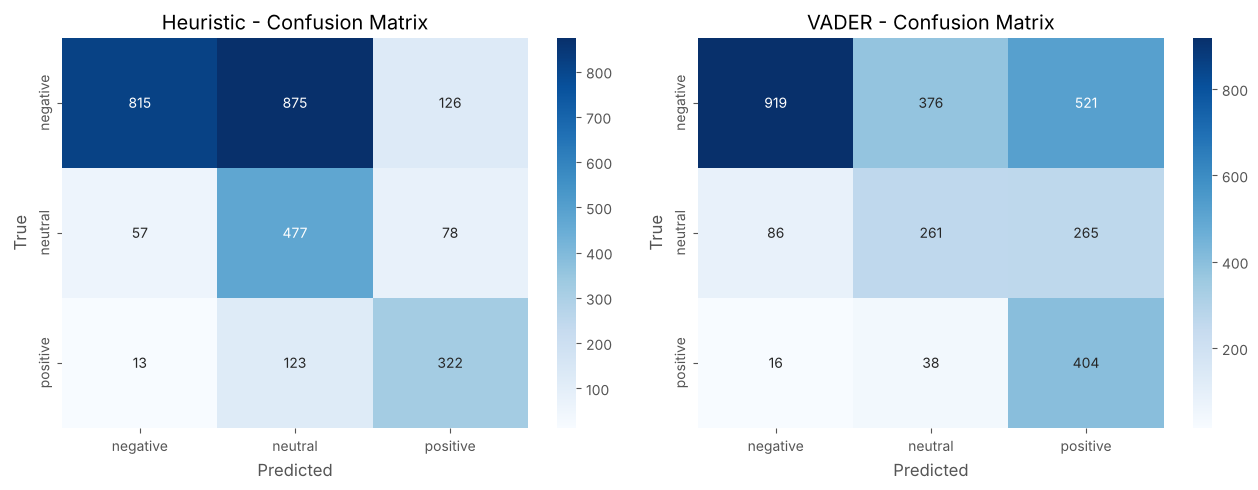

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

for ax, (name, preds) in zip(axes, [('Heuristic', heuristic_predictions), ('VADER', vader_predictions)]):
    cm = confusion_matrix(y_test, preds, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{name} - Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig('screenshots/05_confusion_heuristic_vader.png', dpi=120, bbox_inches='tight')
plt.show()

- Confusion matrices: rows are the true labels and columns are the predictions.

#### Observations (measured, not assumed)

- Both approaches reach only about 55-56% accuracy, which is **below the 63% that a model predicting "negative" every time would get**. Accuracy alone would hide this, so macro-F1 is the better number.
- In this run the simple **heuristic lexicon has a higher macro-F1 than VADER** (about 0.57 vs 0.51). The reason is that the lexicon was written for airline words such as `cancelled`, `flightled` and `hold`, which the general-purpose VADER lexicon does not treat as negative.
- The two tools fail in **different ways**. The heuristic is very precise for the negative class (precision 0.92) but finds fewer than half of the negative tweets (recall 0.45), because many complaints contain no word from the list and are called neutral. VADER over-predicts **positive** (recall 0.88 but precision only 0.34): words such as "thanks", "please" and "help" sound positive in general English even inside complaints.

## 3.5 Where do rules and ready-made tools fail?

In [63]:
failures = {
    9637:  ('Heuristic', "'love how' and 'the best' are positive words, but the writer is sarcastic about a frustrating feedback form. A word list cannot detect sarcasm."),
    5789:  ('Heuristic', "'link doesn't work' is a complaint, but 'work' is not in the lexicon, so no word matches and the tweet becomes neutral. Negating a neutral word is not handled."),
    10257: ('VADER',     "'now on hold for 75 minutes' is negative only in the airline domain. VADER's general lexicon has no negative word here, so it returns neutral."),
    1377:  ('VADER',     "'very glad ... Cancelled Flightled' is irony. VADER sees 'glad' (positive) and does not know that 'Cancelled Flightled' is a complaint, so it predicts positive."),
}

assert all(i in X_test.index for i in failures)   # all four tweets are test tweets

fail_table = pd.DataFrame([
    {
        'Failed approach': who,
        'Tweet': df.loc[i, 'text'],
        'True': df.loc[i, 'airline_sentiment'],
        'Heuristic says': heuristic_sentiment(df.loc[i, 'text']),
        'VADER says': vader_sentiment(df.loc[i, 'text']),
        'Why it failed': why
    }
    for i, (who, why) in failures.items()
])

fail_table

,Failed approach,Tweet,True,Heuristic says,VADER says,Why it failed
0,Heuristic,@USAirways I love how just to give feedback to this link I have to fill out all my personal info on a form. You guys are the best :),negative,positive,positive,"'love how' and 'the best' are positive words, but the writer is sarcastic about a frustrating feedback form. A word list cannot detect sarcasm."
1,Heuristic,@SouthwestAir link doesn't work,negative,neutral,neutral,"'link doesn't work' is a complaint, but 'work' is not in the lexicon, so no word matches and the tweet becomes neutral. Negating a neutral word is not handled."
2,VADER,@USAirways now on hold for 75 minutes.,negative,negative,neutral,"'now on hold for 75 minutes' is negative only in the airline domain. VADER's general lexicon has no negative word here, so it returns neutral."
3,VADER,@united I am very glad I took care of own rescheduling now that UA 1580 from OGG was Cancelled Flightled. http://t.co/H3k3oWOhD1,negative,negative,positive,"'very glad ... Cancelled Flightled' is irony. VADER sees 'glad' (positive) and does not know that 'Cancelled Flightled' is a complaint, so it predicts positive."


- Four real test tweets that were classified wrongly (two per approach) with the cause of each mistake.

#### What this tells us

- Rules and general-purpose tools fail for three reasons: **sarcasm**, **domain words** (`hold`, `Flightled`, `hours`) and **complaints without a sentiment word** ("link doesn't work").
- Fixing each case by hand means adding more rules forever. A model trained on labelled airline tweets can instead **learn** that words such as `hold`, `cancelled` or `not` are connected with negative tweets. That is the motivation for Tasks 4-6.

# Task 4: Feature Extraction — Bag-of-Words, TF-IDF & N-Grams

**Objective:** Convert text into numeric vectors with Bag-of-Words, TF-IDF and N-grams, first by hand and then with scikit-learn.

**Expected output:** Hand-built vs sklearn matrices that match, matrix statistics on the airline tweets, n-gram vocabulary sizes, top bigrams per class and a feature-size experiment.

## 4.1 Why feature extraction

Machine-learning models work with **numbers, not text**. Feature extraction converts every document into a numeric vector so that a classifier can learn from it.

| | Bag-of-Words (BoW) | TF-IDF | N-grams |
|---|---|---|---|
| **What it captures** | How many times each word occurs | Word count weighted by how rare the word is across documents | Counts (or TF-IDF) of sequences of n consecutive words |
| **What it ignores** | Word order and meaning | Word order and meaning (only rarity is added) | Meaning; only short-range order is kept (n words) |
| **Vector size** | Vocabulary size | Vocabulary size | Much larger than the vocabulary (every word pair / triple is a column) |
| **Sparsity** | Very sparse (mostly zeros) | Very sparse | Even sparser |
| **Typical weakness** | Common words dominate; "good, not bad" = "bad, not good" | Still no word order; needs the whole corpus to compute IDF | Vocabulary explosion, memory and over-fitting |

## 4.2 Bag-of-Words by hand and with sklearn

In [64]:
docs = [
    "the flight was good",
    "the flight was not good",
    "the crew was very helpful",
    "the delay was bad but the crew was helpful"
]

docs

['the flight was good',
 'the flight was not good',
 'the crew was very helpful',
 'the delay was bad but the crew was helpful']

In [65]:
from collections import Counter

# Manual Bag-of-Words with Counter
tokens_per_doc = [d.split() for d in docs]
vocab = sorted(set(w for tokens in tokens_per_doc for w in tokens))

bow_manual = pd.DataFrame(
    [[Counter(tokens)[w] for w in vocab] for tokens in tokens_per_doc],
    columns=vocab,
    index=[f"Doc {i+1}" for i in range(len(docs))]
)

bow_manual

,bad,but,crew,delay,flight,good,helpful,not,the,very,was
Doc 1,0,0,0,0,1,1,0,0,1,0,1
Doc 2,0,0,0,0,1,1,0,1,1,0,1
Doc 3,0,0,1,0,0,0,1,0,1,1,1
Doc 4,1,1,1,1,0,0,1,0,2,0,2


In [66]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
bow_sklearn = pd.DataFrame(
    cv.fit_transform(docs).toarray(),
    columns=cv.get_feature_names_out(),
    index=bow_manual.index
)

bow_sklearn

,bad,but,crew,delay,flight,good,helpful,not,the,very,was
Doc 1,0,0,0,0,1,1,0,0,1,0,1
Doc 2,0,0,0,0,1,1,0,1,1,0,1
Doc 3,0,0,1,0,0,0,1,0,1,1,1
Doc 4,1,1,1,1,0,0,1,0,2,0,2


In [67]:
same_columns = list(bow_manual.columns) == list(bow_sklearn.columns)
same_values  = (bow_manual.values == bow_sklearn.values).all()

print("Manual BoW matches CountVectorizer :", same_columns and same_values)

Manual BoW matches CountVectorizer : True


- The hand-made matrix and `CountVectorizer` give the same numbers: each row is a sentence, each column a word, and each cell the word count.

In [68]:
# Why is word order a problem?
pair = ["the movie was good, not bad", "the movie was bad, not good"]

pair_cv = CountVectorizer()
pair_matrix = pair_cv.fit_transform(pair).toarray()

print(pd.DataFrame(pair_matrix, columns=pair_cv.get_feature_names_out(), index=["good, not bad", "bad, not good"]))
print("\nIdentical vectors :", (pair_matrix[0] == pair_matrix[1]).all())

               bad  good  movie  not  the  was
good, not bad    1     1      1    1    1    1
bad, not good    1     1      1    1    1    1

Identical vectors : True


- "the movie was good, not bad" and "the movie was bad, not good" have **opposite meanings** but contain exactly the same words, so Bag-of-Words gives them the **same vector**. BoW only counts words and throws away the order, so it cannot tell which word `not` is attached to.

## 4.3 TF-IDF by hand

In [69]:
# tf = count of the word in the document
counts = bow_manual.values
N = counts.shape[0]                      # number of documents

# df = number of documents that contain the word
doc_freq = (counts > 0).sum(axis=0)

# idf = ln(N / df) + 1
idf = np.log(N / doc_freq) + 1

tfidf_manual = counts * idf

pd.DataFrame({'df': doc_freq, 'idf': idf.round(3)}, index=vocab).T

,bad,but,crew,delay,flight,good,helpful,not,the,very,was
df,1.000,1.000,2.000,1.000,2.000,2.000,2.000,1.000,4.0,1.000,4.0
idf,2.386,2.386,1.693,2.386,1.693,1.693,1.693,2.386,1.0,2.386,1.0


In [70]:
pd.DataFrame(tfidf_manual, columns=vocab, index=bow_manual.index).round(3)

,bad,but,crew,delay,flight,good,helpful,not,the,very,was
Doc 1,0.000,0.000,0.000,0.000,1.693,1.693,0.000,0.000,1.0,0.000,1.0
Doc 2,0.000,0.000,0.000,0.000,1.693,1.693,0.000,2.386,1.0,0.000,1.0
Doc 3,0.000,0.000,1.693,0.000,0.000,0.000,1.693,0.000,1.0,2.386,1.0
Doc 4,2.386,2.386,1.693,2.386,0.000,0.000,1.693,0.000,2.0,0.000,2.0


In [71]:
from sklearn.feature_extraction.text import TfidfVectorizer

# smooth_idf=False and norm=None give exactly the formula above
tv_plain = TfidfVectorizer(smooth_idf=False, norm=None)
tfidf_plain = tv_plain.fit_transform(docs).toarray()

print("Manual TF-IDF equals TfidfVectorizer(smooth_idf=False, norm=None) :", np.allclose(tfidf_manual, tfidf_plain))

Manual TF-IDF equals TfidfVectorizer(smooth_idf=False, norm=None) : True


In [72]:
# The DEFAULT TfidfVectorizer gives different numbers
tv_default = TfidfVectorizer()
tfidf_default = tv_default.fit_transform(docs).toarray()

print("Manual TF-IDF equals default TfidfVectorizer :", np.allclose(tfidf_manual, tfidf_default))

pd.DataFrame(tfidf_default, columns=tv_default.get_feature_names_out(), index=bow_manual.index).round(3)

Manual TF-IDF equals default TfidfVectorizer : False


,bad,but,crew,delay,flight,good,helpful,not,the,very,was
Doc 1,0.000,0.000,0.000,0.000,0.590,0.590,0.000,0.000,0.390,0.000,0.390
Doc 2,0.000,0.000,0.000,0.000,0.472,0.472,0.000,0.599,0.313,0.000,0.313
Doc 3,0.000,0.000,0.472,0.000,0.000,0.000,0.472,0.000,0.313,0.599,0.313
Doc 4,0.395,0.395,0.311,0.395,0.000,0.000,0.311,0.000,0.412,0.000,0.412


In [73]:
# Prove the two differences: (1) smoothed idf  (2) L2 normalisation of every row
idf_smooth = np.log((1 + N) / (1 + doc_freq)) + 1
step1 = counts * idf_smooth
step2 = step1 / np.linalg.norm(step1, axis=1, keepdims=True)

print("Smoothed idf + L2 normalisation reproduce the default output :", np.allclose(step2, tfidf_default))

Smoothed idf + L2 normalisation reproduce the default output : True


- With `smooth_idf=False, norm=None` the library result equals my manual formula.
- The default `TfidfVectorizer()` differs in two ways:
  1. **Smoothing:** `idf = ln((1 + N) / (1 + df)) + 1`. The "+1" inside the logarithm acts as if one extra document containing every word existed, which avoids division by zero for unseen words.
  2. **L2 normalisation:** every row is divided by its length, so each document vector has length 1 and long tweets do not get bigger numbers than short tweets.

#### Why does a word in every document get a low weight?

A word such as `the` or `was` that appears in every document has `df = N`, so `ln(N / df) = ln(1) = 0` and its idf is the minimum value (1 here). A word that appears in only one document (`delay`, `bad`) has the highest idf. TF-IDF therefore down-weights words that do not help to tell documents apart and up-weights the rare, informative words.

## 4.4 BoW and TF-IDF on the airline tweets

In [74]:
# Fit on the TRAINING clean_text only, then transform train and test
bow = CountVectorizer()
X_train_bow = bow.fit_transform(X_train_clean)
X_test_bow  = bow.transform(X_test_clean)

tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf  = tfidf.transform(X_test_clean)

In [75]:
def matrix_stats(name, X_tr, X_te, vectorizer):
    rows, cols = X_tr.shape
    nnz = X_tr.nnz
    return {
        'Method': name,
        'Train shape': X_tr.shape,
        'Test shape': X_te.shape,
        'Vocabulary size': len(vectorizer.vocabulary_),
        'Non-zero entries (train)': nnz,
        'Sparsity %': round(100 * (1 - nnz / (rows * cols)), 3)
    }

pd.DataFrame([
    matrix_stats('Bag-of-Words', X_train_bow, X_test_bow, bow),
    matrix_stats('TF-IDF',       X_train_tfidf, X_test_tfidf, tfidf),
]).set_index('Method')

,Train shape,Test shape,Vocabulary size,Non-zero entries (train),Sparsity %
Method,,,,,
Bag-of-Words,"(11541, 9948)","(2886, 9948)",9948,167327,99.854
TF-IDF,"(11541, 9948)","(2886, 9948)",9948,167327,99.854


- Both matrices have one row per tweet and one column per word. More than 99.8% of the cells are zero because one tweet uses only about 15 of the ~10,000 words, so the matrices are stored as sparse matrices.

In [76]:
# Effect of min_df and max_features on the vocabulary size
settings = {
    'default (all words)':   dict(),
    'min_df=2':              dict(min_df=2),
    'max_features=5000':     dict(max_features=5000),
    'min_df=2 + max_features=5000': dict(min_df=2, max_features=5000),
}

rows = []
for name, params in settings.items():
    v = CountVectorizer(**params).fit(X_train_clean)
    rows.append({'Setting': name, 'Vocabulary size': len(v.vocabulary_)})

pd.DataFrame(rows).set_index('Setting')

,Vocabulary size
Setting,
default (all words),9948
min_df=2,4944
max_features=5000,5000
min_df=2 + max_features=5000,4944


- `min_df=2` removes all words that appear in only one training tweet and cuts the vocabulary roughly in half; `max_features=5000` keeps only the 5,000 most frequent words.

#### Why must the vectoriser be fitted on training data only?

`fit` learns the vocabulary (and for TF-IDF the idf values) from the text it sees. If it were fitted on all tweets, information from the test tweets (their words and document frequencies) would flow into the features that the model trains on. The test score would then be too optimistic because the model has "peeked" at the exam. This is called **data leakage**. By fitting on the training tweets only and only calling `transform` on the test tweets, the test set behaves like truly new tweets (words not seen in training are simply ignored).

## 4.5 N-Grams

In [77]:
ngram_ranges = [(1,1), (1,2), (1,3)]

rows = []
for ng in ngram_ranges:
    v = TfidfVectorizer(ngram_range=ng).fit(X_train_clean)
    rows.append({'ngram_range': str(ng), 'Vocabulary size': len(v.vocabulary_)})

pd.DataFrame(rows).set_index('ngram_range')

,Vocabulary size
ngram_range,
"(1, 1)",9948
"(1, 2)",85118
"(1, 3)",211569


- Adding bigrams multiplies the vocabulary several times; trigrams almost double it again.

In [78]:
# Top 15 highest-weighted bigrams per class: average the TF-IDF rows of each class
tfidf_ng = TfidfVectorizer(ngram_range=(1,2), min_df=2)
X_train_ng = tfidf_ng.fit_transform(X_train_clean)

features = tfidf_ng.get_feature_names_out()
bigram_idx = np.array([i for i, f in enumerate(features) if ' ' in f])   # keep only bigrams

top_bigrams = {}
for label in ['negative', 'positive']:
    rows_of_class = np.where(y_train.values == label)[0]
    mean_tfidf = np.asarray(X_train_ng[rows_of_class].mean(axis=0)).ravel()
    best = bigram_idx[np.argsort(mean_tfidf[bigram_idx])[::-1][:15]]
    top_bigrams[label] = [f"{features[i]} ({mean_tfidf[i]:.4f})" for i in best]

pd.DataFrame(top_bigrams, index=range(1, 16))

,negative,positive
1,on hold (0.0077),thank you (0.0420)
2,can not (0.0069),thanks for (0.0176)
3,customer service (0.0067),for the (0.0128)
4,cancelled flightled (0.0067),you for (0.0099)
5,do not (0.0061),you guys (0.0080)
6,on the (0.0061),so much (0.0077)
7,my flight (0.0056),the best (0.0069)
8,to get (0.0053),customer service (0.0058)
9,hold for (0.0042),for your (0.0053)
10,to be (0.0042),in the (0.0041)


- Shows the 15 bigrams with the highest average TF-IDF weight in the negative and in the positive training tweets.

#### What bigrams add

- **Bigrams carry meaning that single words do not.** Two examples from the output above: (1) `on hold` is the top negative bigram, while the single word `hold` can also be harmless ("hold the door"); `can not` and `do not` are negation phrases that appear in the negative list, whereas the single word `not` alone is very frequent in all classes. (2) `customer service` is one concept, because `customer` and `service` alone are very general words. `thank you`, `so much` and `the best` are typical positive phrases.
- **A weakness is also visible:** the lists contain pairs of stop-words such as `on the` or `for the`, and `customer service` appears in both classes, so a frequent bigram is not automatically a sentiment bigram. The classifier decides how much weight each one gets.
- **Cost of larger n:** the vocabulary explodes (see the table above), the matrix becomes sparser, most n-grams appear only once (so they cannot be learned from), and memory and training time grow. This is why we use `min_df=2` and stop at bigrams.

## 4.6 Feature-size experiment

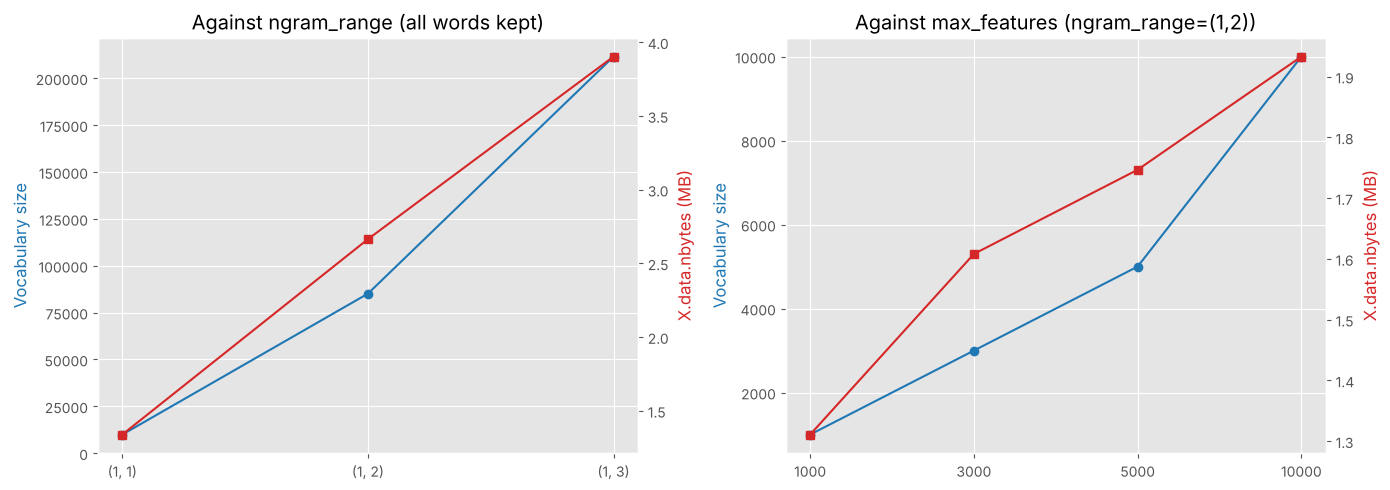

,ngram_range,vocabulary,memory (MB)
0,"(1, 1)",9948,1.34
1,"(1, 2)",85118,2.66
2,"(1, 3)",211569,3.90


In [79]:
def size_in_mb(X):
    return X.data.nbytes / 1e6

# (a) against ngram_range
vocab_ng, mem_ng = [], []
for ng in ngram_ranges:
    v = TfidfVectorizer(ngram_range=ng)
    Xn = v.fit_transform(X_train_clean)
    vocab_ng.append(len(v.vocabulary_))
    mem_ng.append(size_in_mb(Xn))

# (b) against max_features (unigrams + bigrams)
max_feats = [1000, 3000, 5000, 10000]
vocab_mf, mem_mf = [], []
for mf in max_feats:
    v = TfidfVectorizer(ngram_range=(1,2), max_features=mf)
    Xm = v.fit_transform(X_train_clean)
    vocab_mf.append(len(v.vocabulary_))
    mem_mf.append(size_in_mb(Xm))

fig, axes = plt.subplots(1, 2, figsize=(14,5))

for ax, xs, v_list, m_list, title in [
    (axes[0], [str(n) for n in ngram_ranges], vocab_ng, mem_ng, "Against ngram_range (all words kept)"),
    (axes[1], [str(m) for m in max_feats],   vocab_mf, mem_mf, "Against max_features (ngram_range=(1,2))"),
]:
    ax.plot(xs, v_list, marker='o', color='tab:blue', label='Vocabulary size')
    ax.set_ylabel("Vocabulary size", color='tab:blue')
    ax2 = ax.twinx()
    ax2.plot(xs, m_list, marker='s', color='tab:red', label='Matrix memory (MB)')
    ax2.set_ylabel("X.data.nbytes (MB)", color='tab:red')
    ax2.grid(False)
    ax.set_title(title)

plt.tight_layout()
plt.savefig('screenshots/06_feature_size_experiment.png', dpi=120, bbox_inches='tight')
plt.show()

pd.DataFrame({'ngram_range': [str(n) for n in ngram_ranges], 'vocabulary': vocab_ng, 'memory (MB)': np.round(mem_ng, 2)})

- Left: the vocabulary grows very fast with `ngram_range`, but the memory of the non-zero values grows only slowly, because a tweet has only a few words. Right: `max_features` simply caps the vocabulary; memory increases a little more slowly than the number of features.

#### How would I choose a sensible setting?

I would look for the point where the vocabulary and memory keep growing but the **macro-F1 on training data (cross-validation)** stops improving. In this project, `ngram_range=(1,2)` with `min_df=2` gives a vocabulary of about 23,000 features (22,825 features in Task 6.2) instead of the 211,569 features of trigrams without a cut-off, and Task 6 shows that it scores better than unigrams alone. The setting is chosen by experiments (never by looking at the test set) and balanced against memory, speed and over-fitting.

# Task 5: Word Embeddings, Word2Vec — CBoW & Skip-gram

**Objective:** Learn dense word vectors with Word2Vec (CBoW and Skip-gram) and turn every tweet into one numeric vector.

**Expected output:** Two trained Word2Vec models, a similar-word table, cosine similarities, a 2-D PCA plot and document-vector features for the train and test tweets.

## 5.1 Word embeddings

BoW and TF-IDF treat every word as an **unrelated column**: `delayed` and `late` are two different columns with nothing in common, and each vector is huge and mostly zeros (sparse), with no meaning.

A **word embedding** places every word as a short **dense vector** (here 100 numbers) in such a way that words used in similar contexts get similar vectors. The idea behind it is the famous sentence: *"a word is known by the company it keeps."* Because `delayed` and `late` appear next to similar words (`flight`, `hours`, `again`), their vectors end up close to each other, and the distance between vectors becomes a measure of similarity in meaning.

## 5.2 CBoW vs Skip-gram

Word2Vec is a small neural network that learns the vectors by solving a prediction task:

- **CBoW (Continuous Bag-of-Words)** predicts the **centre word** from the words around it.
- **Skip-gram** predicts the **context words** from the centre word.

| | CBoW | Skip-gram |
|---|---|---|
| **Input** | The surrounding context words | The centre word |
| **Output** | The centre word | Each of the context words |
| **Training speed** | Faster (one prediction per position) | Slower (up to 2 × window predictions per position) |
| **Performance on rare words** | Weaker (a rare word is averaged with its context and gets few updates) | Better (every occurrence gives several training pairs) |
| **Performance on frequent words** | Good | Good |
| **When to prefer** | Big corpus, speed matters, mostly frequent words | Smaller corpus, rare words matter |

In [80]:
# Training pairs for "the flight was delayed again" with window = 2
sentence = "the flight was delayed again".split()
window = 2

cbow_pairs, skipgram_pairs = [], []

for i, centre in enumerate(sentence):
    context = [sentence[j] for j in range(max(0, i - window), min(len(sentence), i + window + 1)) if j != i]
    cbow_pairs.append((context, centre))
    skipgram_pairs.extend((centre, c) for c in context)

print("CBoW  (context -> centre)")
for context, centre in cbow_pairs:
    print(f"  {str(context):45s} -> {centre}")

print("\nSkip-gram  (centre -> context)")
for centre, c in skipgram_pairs:
    print(f"  {centre:8s} -> {c}")

CBoW  (context -> centre)
  ['flight', 'was']                             -> the
  ['the', 'was', 'delayed']                     -> flight
  ['the', 'flight', 'delayed', 'again']         -> was
  ['flight', 'was', 'again']                    -> delayed
  ['was', 'delayed']                            -> again

Skip-gram  (centre -> context)
  the      -> flight
  the      -> was
  flight   -> the
  flight   -> was
  flight   -> delayed
  was      -> the
  was      -> flight
  was      -> delayed
  was      -> again
  delayed  -> flight
  delayed  -> was
  delayed  -> again
  again    -> was
  again    -> delayed


- The same sentence gives **5 CBoW examples** (one per centre word, with all context words together as input) but **14 Skip-gram examples** (one per centre-context pair). This is why Skip-gram is slower but learns more from each rare word.

## 5.3 Train both models

In [81]:
from gensim.models import Word2Vec
import time

# token lists of the TRAINING tweets only (stop-words are kept: Word2Vec learns from the words around a word)
train_tokens = df.loc[X_train.index, 'tokens'].tolist()
test_tokens  = df.loc[X_test.index,  'tokens'].tolist()

print("Training tweets :", len(train_tokens))
print("Total tokens    :", sum(len(t) for t in train_tokens))

Training tweets : 11541
Total tokens    : 188164


In [82]:
# CBoW
start = time.perf_counter()
w2v_cbow = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=3,
                    sg=0, epochs=20, seed=42, workers=1)
cbow_time = time.perf_counter() - start

# Skip-gram
start = time.perf_counter()
w2v_sg = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=3,
                  sg=1, epochs=20, seed=42, workers=1)
sg_time = time.perf_counter() - start

pd.DataFrame({
    'Model': ['CBoW (sg=0)', 'Skip-gram (sg=1)'],
    'Vocabulary size': [len(w2v_cbow.wv), len(w2v_sg.wv)],
    'Vector shape': [w2v_cbow.wv['flight'].shape, w2v_sg.wv['flight'].shape],
    'Training time (s)': [round(cbow_time, 2), round(sg_time, 2)]
}).set_index('Model')

,Vocabulary size,Vector shape,Training time (s)
Model,,,
CBoW (sg=0),3683,"(100,)",3.46
Skip-gram (sg=1),3683,"(100,)",10.47


- Hyper-parameters (same for both): `vector_size=100, window=5, min_count=3, epochs=20, seed=42, workers=1` (`workers=1` and the seed make the result repeatable). Only `sg` differs.
- Words that occur fewer than 3 times in the training tweets are ignored. Skip-gram takes clearly longer to train than CBoW, as expected.

## 5.4 Explore the vectors

In [83]:
query_words = ['delayed', 'flight', 'thanks', 'rude', 'luggage', 'great']

similar_table = pd.DataFrame({
    'Word': query_words,
    'CBoW - 5 most similar':      [", ".join(w for w, _ in w2v_cbow.wv.most_similar(q, topn=5)) for q in query_words],
    'Skip-gram - 5 most similar': [", ".join(w for w, _ in w2v_sg.wv.most_similar(q, topn=5))   for q in query_words],
}).set_index('Word')

similar_table

,CBoW - 5 most similar,Skip-gram - 5 most similar
Word,,
delayed,"late, delay, missed, leaving, scheduled","departed, apt, inbound, grounded, redirected"
flight,"flt, connection, cun, flights, meeting","ind, previously, diverted, nite, nola"
thanks,"thx, thank, appreciate, shoutout, quick","thx, thnx, thank, prompt, responses"
rude,"helpful, friendly, unhelpful, unprofessional, staff","unprofessional, karen, unhelpful, pleasant, appalled"
luggage,"bag, bags, mom, baggage, husband","bag, bags, belongings, carousel, baggage"
great,"awesome, excellent, wonderful, fantastic, btw","wonderful, awesome, fantastic, job, views"


In [84]:
# Cosine similarity of word pairs (a word that is not in the vocabulary is reported, not crashed on)
def pair_similarity(model, a, b):
    if a in model.wv and b in model.wv:
        return round(float(model.wv.similarity(a, b)), 3)
    return "not in vocabulary"

pairs = [('delayed', 'late'), ('good', 'great'), ('flight', 'birthday'), ('flight', 'banana')]

pd.DataFrame({
    'Word pair': [f"{a} - {b}" for a, b in pairs],
    'CBoW': [pair_similarity(w2v_cbow, a, b) for a, b in pairs],
    'Skip-gram': [pair_similarity(w2v_sg, a, b) for a, b in pairs],
}).set_index('Word pair')

,CBoW,Skip-gram
Word pair,,
delayed - late,0.652,0.508
good - great,0.383,0.444
flight - birthday,0.12,0.263
flight - banana,not in vocabulary,not in vocabulary


- `delayed - late` and `good - great` are related pairs and `flight - birthday` is unrelated. `banana` appears fewer than 3 times in the tweets, so it has no vector at all (this is the `min_count` effect).

#### Are the neighbours sensible?

- **Mostly yes, and the two models are good at different things.** CBoW gives very sensible neighbours for `delayed` (late, delay, missed, leaving), `thanks` (thx, thank, appreciate) and `great` (awesome, excellent, wonderful, fantastic). Skip-gram is better for `luggage` (bag, bags, belongings, carousel, baggage) and `rude` (unprofessional, unhelpful, appalled), but its neighbours for `delayed` and `flight` are rare words such as airport codes (apt, inbound, ind, nola) that only share a rare context.
- **Noise is visible:** CBoW lists `mom` and `husband` next to `luggage`, and `rude` has `helpful` and `friendly` as neighbours: opposites appear in the same contexts ("the staff was ___"), so Word2Vec cannot separate opposites well.
- **Cosine similarity:** for the related pair `delayed - late` CBoW gives 0.65 against 0.51 for Skip-gram, and for the unrelated pair `flight - birthday` CBoW gives 0.12 against 0.26. CBoW therefore separates related from unrelated words more clearly.
- **Honest limitation:** this corpus is small (about 188,000 training tokens), so the vectors are **noisier** than vectors trained on billions of words and the numbers should not be over-interpreted. `banana` occurs fewer than 3 times, so it has no vector at all.
- **Choice:** I use the **CBoW** model for the document vectors in 5.6 because of its cleaner neighbours and cosine values for the frequent words that matter in tweets, and because it trains about three times faster.

## 5.5 Visualise embeddings

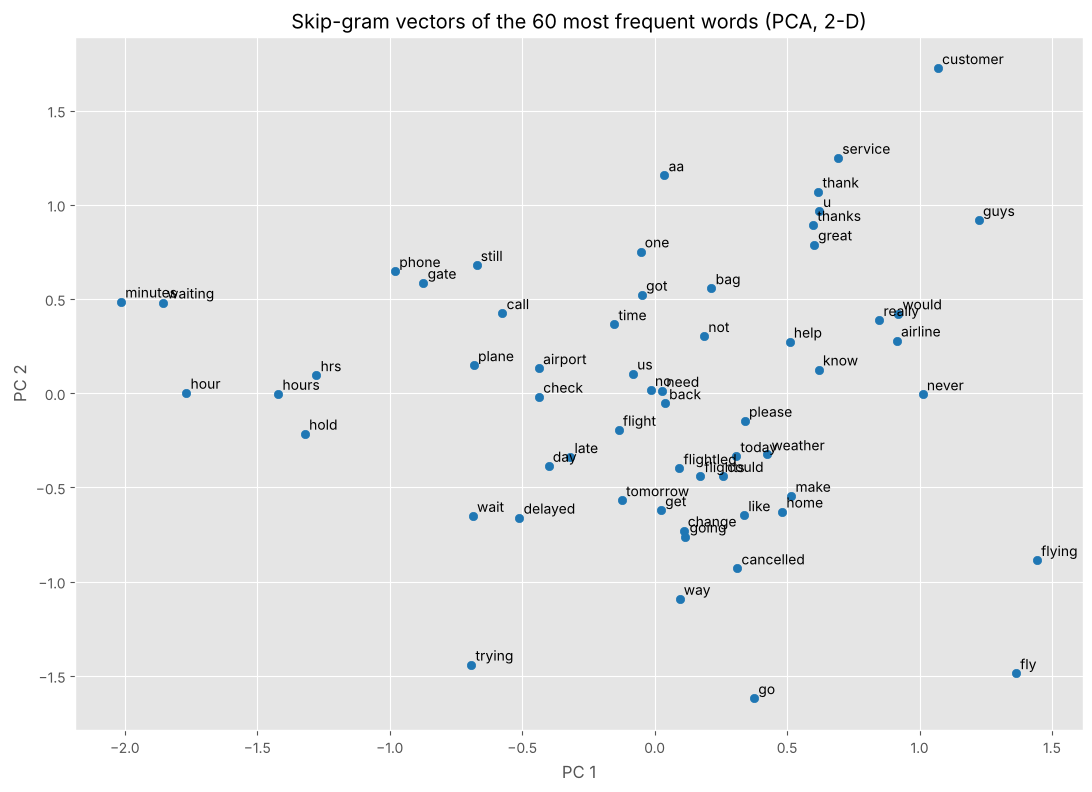

Variance explained by the 2 components : [0.056 0.046] -> 0.102


In [85]:
from sklearn.decomposition import PCA

# 60 most frequent words (gensim keeps the vocabulary sorted by frequency); stop-words are skipped so that
# the plot shows content words instead of "the", "to", "a" ...
top60 = [w for w in w2v_sg.wv.index_to_key if w not in stop_words][:60]

vectors = np.array([w2v_sg.wv[w] for w in top60])

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(vectors)

plt.figure(figsize=(13,9))
plt.scatter(coords[:,0], coords[:,1], color='tab:blue')

for word, (x_, y_) in zip(top60, coords):
    plt.annotate(word, (x_, y_), fontsize=10, xytext=(3,3), textcoords='offset points')

plt.title("Skip-gram vectors of the 60 most frequent words (PCA, 2-D)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.savefig('screenshots/07_word2vec_pca.png', dpi=120, bbox_inches='tight')
plt.show()

print("Variance explained by the 2 components :", pca.explained_variance_ratio_.round(3), "->", round(pca.explained_variance_ratio_.sum(), 3))

- Each dot is a word; words with similar vectors lie close together. Two components keep only a small part of the 100-dimensional information, so the picture is a rough guide only.

#### Clusters seen in the plot

- **Waiting-time words** (minutes, waiting, hour, hours, hrs, hold, phone, gate, still) form a group on the far left: they all describe being kept waiting.
- **Thank-you and service words** (thank, thanks, great, customer, service, guys) lie together in the upper right.
- **Delay and cancellation words** (delayed, wait, late, cancelled, flightled, flights) sit close to each other in the lower middle.
- **Verbs of travel** (fly, flying, go) are separated on the lower right.
- Only 10% of the variance is shown, so some words that look close (for example `no` and `need`) are not necessarily close in 100 dimensions.

## 5.6 From word vectors to document vectors

In [86]:
def doc_vector(tokens, model):
    """Average the vectors of the tokens that are in the vocabulary; zeros if none is."""
    vectors = [model.wv[t] for t in tokens if t in model.wv.key_to_index]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

best_w2v = w2v_cbow          # chosen in 5.4

X_train_w2v = np.array([doc_vector(t, best_w2v) for t in train_tokens])
X_test_w2v  = np.array([doc_vector(t, best_w2v) for t in test_tokens])

print("X_train_w2v :", X_train_w2v.shape)
print("X_test_w2v  :", X_test_w2v.shape)
print("Tweets with no known word (zero vector) in test :", int((~X_test_w2v.any(axis=1)).sum()))

X_train_w2v : (11541, 100)
X_test_w2v  : (2886, 100)
Tweets with no known word (zero vector) in test : 5


- Every tweet becomes one **dense** vector of 100 numbers (instead of ~10,000 sparse columns). The Word2Vec model was trained on the training tweets only; the test tweets are only transformed. These features are used in Task 6.

#### What information is lost when averaging word vectors?

- **Word order is lost** ("not good" and "good, not" get the same average), so negation is only weakly captured.
- All words get the same weight: a strong word such as `cancelled` is averaged together with many neutral words, so its signal is diluted in long tweets.
- Words that are not in the vocabulary are ignored completely, and the vectors of opposites (`good`/`bad`) are close, so the average cannot separate them well.

# Task 6: Text Classification Pipeline & Approach Comparison

**Objective:** Train and compare several feature / classifier combinations on the same split and compare them with the heuristic and API-based approaches.

**Expected output:** A baseline pipeline, a results table with 6 combinations, a bar chart of all approaches, cross-validation, error analysis and a saved model file.

## 6.1 Text classification and the pipeline

**Text classification** means assigning one label from a fixed set to a whole document. Here the document is a tweet and the label is `negative`, `neutral` or `positive`.

The classification pipeline of this project, stage by stage:

1. **Raw text** – the tweet exactly as written (`text` column).
2. **Cleaning** – `clean_text()` (Task 2) lower-cases and removes URLs, mentions, numbers and punctuation.
3. **Features** – a vectoriser turns the cleaned text into numbers (BoW, TF-IDF, N-grams, or averaged Word2Vec).
4. **Classifier** – Logistic Regression, Naive Bayes or Linear SVM learns the connection between numbers and labels from the training tweets.
5. **Prediction** – for a new tweet, the same cleaning and features are applied and the classifier returns a label (and probabilities).
6. **Evaluation** – accuracy, macro-F1, per-class precision / recall and the confusion matrix on the unseen test tweets.

**Why use a scikit-learn `Pipeline`?** It chains the vectoriser and the classifier into one object. `pipeline.fit(train)` fits the vectoriser **on the training tweets only** and passes the result to the classifier; inside cross-validation it re-fits the vectoriser for every fold, so no vocabulary or idf value leaks from the validation part. For deployment, one `joblib` file contains both steps, so the app cannot forget to apply the same vectoriser that was used in training.

## 6.2 Build the baseline pipeline

In [87]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2)),
    ('clf',   LogisticRegression(max_iter=1000, class_weight='balanced'))
])

start = time.perf_counter()
baseline.fit(X_train_clean, y_train)
baseline_time = time.perf_counter() - start

baseline_pred = baseline.predict(X_test_clean)

print("Accuracy :", round(accuracy_score(y_test, baseline_pred), 4))
print("Macro-F1 :", round(f1_score(y_test, baseline_pred, average='macro'), 4))
print()
print(classification_report(y_test, baseline_pred, digits=3))

Accuracy : 0.7997
Macro-F1 : 0.7534

              precision    recall  f1-score   support

    negative      0.892     0.850     0.871      1816
     neutral      0.610     0.683     0.645       612
    positive      0.735     0.755     0.745       458

    accuracy                          0.800      2886
   macro avg      0.746     0.763     0.753      2886
weighted avg      0.808     0.800     0.803      2886



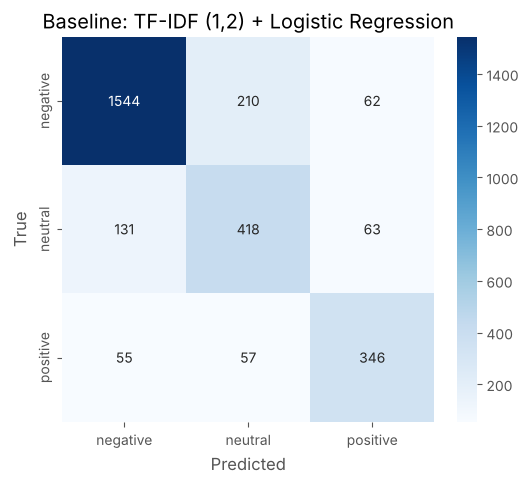

In [88]:
cm = confusion_matrix(y_test, baseline_pred, labels=labels)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Baseline: TF-IDF (1,2) + Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.savefig('screenshots/08_baseline_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

In [89]:
# A quick illustration of what class_weight does (same model without balancing)
no_weight = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2)),
    ('clf',   LogisticRegression(max_iter=1000))
]).fit(X_train_clean, y_train)

nw_pred = no_weight.predict(X_test_clean)

cw = pd.DataFrame([
    evaluate("class_weight='balanced'", y_test, baseline_pred),
    evaluate("class_weight=None",       y_test, nw_pred),
]).set_index('Approach')

cw[['Accuracy', 'Macro-F1', 'Recall (neg)', 'Recall (neu)', 'Recall (pos)']].round(3)

,Accuracy,Macro-F1,Recall (neg),Recall (neu),Recall (pos)
Approach,,,,,
class_weight='balanced',0.800,0.753,0.850,0.683,0.755
class_weight=None,0.802,0.724,0.957,0.485,0.611


#### Why `class_weight='balanced'` for this dataset?

About 63% of the tweets are negative. Without weights the classifier can lower its error mostly by getting the big negative class right and neglecting the small neutral and positive classes. `class_weight='balanced'` multiplies the loss of each class by `n_samples / (n_classes × n_samples_of_that_class)`, so a mistake on a rare class costs more. The table above shows the effect: the recall of the neutral and positive classes goes up, which is what macro-F1 rewards (the price is a slightly lower accuracy).

## 6.3 Compare feature approaches

In [90]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

def lr():
    return LogisticRegression(max_iter=1000, class_weight='balanced')

candidates = {
    '(a)': ('Bag-of-Words',            'Multinomial Naive Bayes',  Pipeline([('vec', CountVectorizer()),                          ('clf', MultinomialNB())])),
    '(b)': ('Bag-of-Words',            'Logistic Regression',      Pipeline([('vec', CountVectorizer()),                          ('clf', lr())])),
    '(c)': ('TF-IDF unigrams',         'Logistic Regression',      Pipeline([('vec', TfidfVectorizer()),                          ('clf', lr())])),
    '(d)': ('TF-IDF unigrams+bigrams', 'Logistic Regression',      Pipeline([('vec', TfidfVectorizer(ngram_range=(1,2), min_df=2)), ('clf', lr())])),
    '(f)': ('TF-IDF unigrams+bigrams', 'Linear SVM',               Pipeline([('vec', TfidfVectorizer(ngram_range=(1,2), min_df=2)), ('clf', LinearSVC(class_weight='balanced'))])),
}

def result_row(features, classifier, y_pred, train_time):
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=labels, zero_division=0)
    return {
        'Features': features,
        'Classifier': classifier,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro-F1': f1_score(y_test, y_pred, average='macro'),
        'Precision (negative)': p[0],
        'Recall (positive)': r[2],
        'Training time (s)': train_time
    }

rows, fitted = {}, {}

for key, (features, classifier, pipe) in candidates.items():
    start = time.perf_counter()
    pipe.fit(X_train_clean, y_train)
    elapsed = time.perf_counter() - start
    rows[key] = result_row(features, classifier, pipe.predict(X_test_clean), elapsed)
    fitted[key] = pipe

In [91]:
# (e) Word2Vec averaged vectors (CBoW) + Logistic Regression
w2v_lr = LogisticRegression(max_iter=2000, class_weight='balanced')

start = time.perf_counter()
w2v_lr.fit(X_train_w2v, y_train)
elapsed = (time.perf_counter() - start) + cbow_time          # classifier + training the CBoW model

rows['(e)'] = result_row('Word2Vec (CBoW, averaged)', 'Logistic Regression', w2v_lr.predict(X_test_w2v), elapsed)
fitted['(e)'] = None          # not a text pipeline (features were built separately)

results_table = pd.DataFrame(rows).T.loc[['(a)','(b)','(c)','(d)','(e)','(f)']]
for col in ['Accuracy','Macro-F1','Precision (negative)','Recall (positive)','Training time (s)']:
    results_table[col] = results_table[col].astype(float)

results_table.style.format({
    'Accuracy': '{:.4f}', 'Macro-F1': '{:.4f}', 'Precision (negative)': '{:.4f}',
    'Recall (positive)': '{:.4f}', 'Training time (s)': '{:.2f}'
}).highlight_max(subset=['Macro-F1'], color='lightgreen')

,Features,Classifier,Accuracy,Macro-F1,Precision (negative),Recall (positive),Training time (s)
(a),Bag-of-Words,Multinomial Naive Bayes,0.7699,0.6709,0.7798,0.5852,0.24
(b),Bag-of-Words,Logistic Regression,0.7678,0.7247,0.8955,0.7598,0.76
(c),TF-IDF unigrams,Logistic Regression,0.7741,0.7319,0.8881,0.7686,0.43
(d),TF-IDF unigrams+bigrams,Logistic Regression,0.7997,0.7534,0.8925,0.7555,0.80
(e),"Word2Vec (CBoW, averaged)",Logistic Regression,0.7013,0.6569,0.8780,0.7293,3.91
(f),TF-IDF unigrams+bigrams,Linear SVM,0.8035,0.7456,0.8624,0.7140,0.64


- All candidates use the same stratified split. The best macro-F1 is highlighted in green. No setting was tuned on the test set; the test set was used once to compare these six fixed candidates.

#### Observations

- **TF-IDF unigrams + bigrams with Logistic Regression (d) has the best macro-F1 (0.753)**. Linear SVM reaches a slightly higher accuracy (0.804) but a lower macro-F1 (0.746), and it cannot give class probabilities, which the app needs.
- **TF-IDF beats Bag-of-Words** with the same classifier (0.732 vs 0.725), because it down-weights very common words; **adding bigrams helps further** (+0.02).
- **Naive Bayes** has an accuracy similar to Logistic Regression (0.770) but a much lower macro-F1 (0.671): its recall for the positive class is only 0.585, because it follows the large negative class and has no class weighting. It is the fastest to train.
- **Averaged Word2Vec is the weakest ML option (0.657)**: the corpus is small, and averaging throws away word order and negation (see 5.6).
- All models train in a few seconds, so training time does not decide the choice here.

## 6.4 Compare all three NLP approaches

In [92]:
best_bow_key = results_table.loc[['(a)','(b)']]['Macro-F1'].idxmax()

comparison_rows = [
    ('Heuristic',  'Rule-based lexicon (3.2)',               approach_results.loc['Heuristic (own lexicon)', 'Accuracy'], approach_results.loc['Heuristic (own lexicon)', 'Macro-F1']),
    ('API-based',  'VADER (3.3)',                            approach_results.loc['API-based (VADER)', 'Accuracy'],       approach_results.loc['API-based (VADER)', 'Macro-F1']),
    ('BoW',        f"{results_table.loc[best_bow_key,'Classifier']} {best_bow_key}", results_table.loc[best_bow_key, 'Accuracy'], results_table.loc[best_bow_key, 'Macro-F1']),
    ('TF-IDF',     'TF-IDF unigrams + Logistic Regression (c)', results_table.loc['(c)', 'Accuracy'], results_table.loc['(c)', 'Macro-F1']),
    ('N-gram',     'TF-IDF (1,2) + Logistic Regression (d)',    results_table.loc['(d)', 'Accuracy'], results_table.loc['(d)', 'Macro-F1']),
    ('Word2Vec',   'CBoW averaged + Logistic Regression (e)',   results_table.loc['(e)', 'Accuracy'], results_table.loc['(e)', 'Macro-F1']),
]

all_approaches = pd.DataFrame(comparison_rows, columns=['Approach', 'Method', 'Accuracy', 'Macro-F1']).set_index('Approach')

all_approaches.round(4)

,Method,Accuracy,Macro-F1
Approach,,,
Heuristic,Rule-based lexicon (3.2),0.5590,0.5720
API-based,VADER (3.3),0.5490,0.5150
BoW,Logistic Regression (b),0.7678,0.7247
TF-IDF,TF-IDF unigrams + Logistic Regression (c),0.7741,0.7319
N-gram,"TF-IDF (1,2) + Logistic Regression (d)",0.7997,0.7534
Word2Vec,CBoW averaged + Logistic Regression (e),0.7013,0.6569


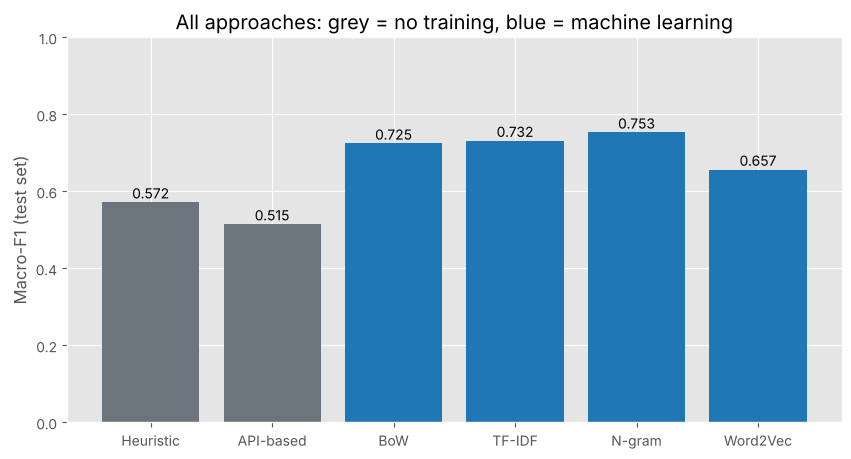

In [93]:
bar_colors = ['#6c757d', '#6c757d', '#1f77b4', '#1f77b4', '#1f77b4', '#1f77b4']

plt.figure(figsize=(10,5))
bars = plt.bar(all_approaches.index, all_approaches['Macro-F1'], color=bar_colors)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{bar.get_height():.3f}", ha='center')

plt.ylim(0, 1)
plt.ylabel("Macro-F1 (test set)")
plt.title("All approaches: grey = no training, blue = machine learning")
plt.savefig('screenshots/09_all_approaches_macro_f1.png', dpi=120, bbox_inches='tight')
plt.show()

#### Ranking and decision

| Rank | Approach | Macro-F1 | Why |
|---|---|---|---|
| 1 | N-gram (TF-IDF 1-2 grams + LR) | 0.753 | Learns airline words *and* short phrases such as `on hold`, `can not` from labelled tweets |
| 2 | TF-IDF (unigrams + LR) | 0.732 | Learns the domain words, down-weights common words |
| 3 | BoW (+ LR) | 0.725 | Learns the domain words, but common words dominate |
| 4 | Word2Vec (averaged + LR) | 0.657 | Dense meaning, but a small corpus and averaging lose order and negation |
| 5 | Heuristic | 0.572 | Knows my airline words, but sarcasm and unseen words break it |
| 6 | API-based (VADER) | 0.515 | General-purpose lexicon does not know airline words |

- **The three approaches that learn from labelled airline tweets all beat the two "no training" approaches**, by a large margin (0.65-0.75 vs 0.52-0.57). Domain data matters more than a clever general tool.
- The lexicon heuristic beat VADER because the word list was written for this domain, but it is limited to the words I thought of.
- **I would deploy TF-IDF (1,2) + Logistic Regression**: best macro-F1, it returns probabilities for the app, trains in about a second, is small and fast at prediction time and is easy to explain through its word weights. The heuristic and VADER stay in the app as comparison options. In a company without labelled data, I would start with VADER or the heuristic and collect labels to train the ML model later.

## 6.5 Cross-validation of the best pipeline

In [94]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

best_key = results_table['Macro-F1'].idxmax()
best_pipe = fitted[best_key]
assert best_pipe is not None, "the best model must be a text pipeline (vectoriser + classifier)"

print("Best pipeline :", results_table.loc[best_key, 'Features'], "+", results_table.loc[best_key, 'Classifier'])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# cross-validation on the TRAINING tweets only; the vectoriser is re-fitted inside every fold
cv_scores = cross_val_score(best_pipe, X_train_clean, y_train, cv=cv, scoring='f1_macro')

print("Fold scores        :", cv_scores.round(4))
print(f"CV macro-F1        : {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print(f"Test macro-F1      : {results_table.loc[best_key, 'Macro-F1']:.4f}")

Best pipeline : TF-IDF unigrams+bigrams + Logistic Regression


Fold scores        : [0.7276 0.744  0.739  0.7307 0.7397]
CV macro-F1        : 0.7362 +/- 0.0061
Test macro-F1      : 0.7534


- The 5-fold cross-validation macro-F1 on the training tweets is **0.736 ± 0.006**, and the test macro-F1 is **0.753**. The gap is only about 0.017, so the model is **stable and not over-fitted**. The test score is a little higher because every CV model learns from only 80% of the training tweets and because one test set of 2,886 tweets is a single sample with its own random variation.
- **What a large gap would mean:** a CV score much higher than the test score would suggest over-fitting to the training data, data leakage (for example a vectoriser fitted on all data) or a test set that is different from the training data; a big difference between folds (large standard deviation) would show that the model is unstable.

## 6.6 Error analysis

In [95]:
# The app needs class probabilities, so the final model must have predict_proba
final_pipeline = best_pipe if hasattr(best_pipe, 'predict_proba') else baseline

proba = final_pipeline.predict_proba(X_test_clean)
final_pred = final_pipeline.classes_[proba.argmax(axis=1)]

errors = pd.DataFrame({
    'Tweet': X_test.values,
    'True label': y_test.values,
    'Predicted': final_pred,
    'Probability': proba.max(axis=1).round(3),
    'Words': X_test_clean.str.split().str.len().values
}, index=X_test.index)

errors = errors[errors['True label'] != errors['Predicted']]

print("Misclassified test tweets :", len(errors), "of", len(X_test))

# the 8 most confident mistakes
errors.sort_values('Probability', ascending=False).head(8).drop(columns='Words')

Misclassified test tweets : 578 of 2886


,Tweet,True label,Predicted,Probability
11995,@AmericanAir thanks!,neutral,positive,0.996
1054,"@united 8602947, jon at http://t.co/58tuTgli0D, thanks.",neutral,positive,0.988
6232,@SouthwestAir Thank you.,neutral,positive,0.988
11910,"@AmericanAir Thank you, you too!",neutral,positive,0.980
4343,@SouthwestAir I have been on hold for over 28 minutes please help http://t.co/Fx9BIJlxAt,neutral,negative,0.967
9010,@USAirways we even offered to fly in to another airport and they said they couldn't do that. No explanation why they can't.,neutral,negative,0.917
2008,@united Thanks! Good to know.,neutral,positive,0.911
1177,@united just confirmed a seat! Crisis averted! Beers won't be missed now,positive,negative,0.905


In [96]:
# Which classes are confused?
print(pd.crosstab(errors['True label'], errors['Predicted'], rownames=['True'], colnames=['Predicted']))

# Are short tweets harder?
test_lengths = X_test_clean.str.split().str.len()
short = test_lengths <= 5

print("\nError rate, tweets with <= 5 words :", round(100 * (errors['Words'] <= 5).sum() / short.sum(), 1), "%")
print("Error rate, longer tweets          :", round(100 * (errors['Words'] > 5).sum() / (~short).sum(), 1), "%")

Predicted  negative  neutral  positive
True                                  
negative          0      210        62
neutral         131        0        63
positive         55       57         0

Error rate, tweets with <= 5 words : 22.8 %
Error rate, longer tweets          : 19.7 %


#### Error patterns

The model makes 578 mistakes in 2,886 test tweets (20%). **About 80% of them involve the neutral class** (negative→neutral 210, neutral→negative 131, neutral→positive 63, positive→neutral 57); positive vs negative mix-ups are rare. Neutral is the smallest-but-one class, has no clear vocabulary and is hard for humans too.

1. **Neutral vs positive – "thank you" tweets.** Five of the 8 most confident mistakes are short thank-you tweets that the annotators labelled neutral ("Thanks!", "Thank you."), but the model predicts positive with 98-99% confidence. This is understandable: in the data, 127 of 152 short tweets with *thank* are positive and only 24 neutral, so the model follows the majority.
2. **Probable label noise.** "I have been on hold for over 28 minutes please help" and "they said they couldn't do that. No explanation why" are labelled neutral, but read as complaints. The model's negative prediction is arguably right.
3. **Mixed sentiment.** "Crisis averted! Beers won't be missed now" is positive, but the words `crisis` and `missed` pull the model to negative (a bag of words cannot see that they are negated or resolved).
4. **Very short tweets.** The error rate is 22.8% for tweets with 5 words or fewer and 19.7% for longer tweets: less text gives less evidence, but the difference is small.

#### Two improvement ideas within this practical

- **Keep `?` and `!` as tokens** instead of deleting them in `clean_text()`: questions ("what is the baggage allowance?") are usually neutral and exclamation marks mark strong feelings, which could help to separate neutral from the other classes.
- **Tune `min_df`, `ngram_range` (for example (1,3)) and the regularisation strength `C` with cross-validation on the training data** (never on the test set), and add the clearer phrases such as "thank you very much" that trigrams capture.

## 6.7 Save the final pipeline

In [97]:
import joblib
import sklearn

joblib.dump(final_pipeline, 'sentiment_model.joblib')

print("Saved sentiment_model.joblib")
print("scikit-learn version used :", sklearn.__version__)

Saved sentiment_model.joblib
scikit-learn version used : 1.9.1


In [98]:
# Reload in a fresh object and predict 3 new sentences (cleaning is done separately with clean_text)
loaded_model = joblib.load('sentiment_model.joblib')

new_sentences = [
    "The crew was friendly and the flight landed early, thank you!",
    "I am not happy with the delay, nobody at the gate could help",
    "What is the baggage allowance for my ticket?"
]

cleaned = [clean_text(s) for s in new_sentences]
probabilities = loaded_model.predict_proba(cleaned)

pd.DataFrame({
    'Sentence': new_sentences,
    'Prediction': loaded_model.predict(cleaned),
    'Confidence': probabilities.max(axis=1).round(3)
})

,Sentence,Prediction,Confidence
0,"The crew was friendly and the flight landed early, thank you!",positive,0.904
1,"I am not happy with the delay, nobody at the gate could help",negative,0.797
2,What is the baggage allowance for my ticket?,neutral,0.598


- The saved file contains the **vectoriser and the classifier together**. The `scikit-learn` version printed above must be written into `requirements.txt` (Task 8.6), because a model saved with one version may not load, or may behave differently, in another version.

# Task 7: POS Tagging

**Objective:** Understand how part-of-speech tagging works, apply NLTK's tagger to tweets and test whether POS information helps the classifier.

**Expected output:** Tagged example sentences, a POS-distribution chart per sentiment class, top adjectives per class and a macro-F1 comparison of a POS-filtered pipeline with the full-text pipeline.

## 7.1 What is POS tagging

**Part-of-speech (POS) tagging** means labelling every word of a sentence with its grammatical role. Common tags and the Penn Treebank codes that NLTK returns:

| Part of speech | Penn Treebank code | Example |
|---|---|---|
| Noun | `NN` (singular), `NNS` (plural) | flight, bags |
| Verb | `VB` (base), `VBD` (past), `VBG` (-ing), `VBN` (past participle) | book, delayed |
| Adjective | `JJ` | rude, great |
| Adverb | `RB` | very, never, not |
| Pronoun | `PRP` | I, they |
| Preposition | `IN` | at, with, for |

**Why is it useful?**
- *Information extraction* – find nouns and proper nouns (what the complaint is about).
- *Grammar checking* – detect a wrong verb form.
- *Better features* – keep only the sentiment-carrying words (adjectives, adverbs, verbs).
- *Disambiguation* – the same word can have different meanings: "book a flight" (verb) vs "read a book" (noun).

## 7.2 How POS tagging works

1. **Rule-based tagger** – uses a dictionary and hand-written rules ("a word after *the* is probably a noun", "a word ending in *-ly* is probably an adverb"). Simple, but a rule list can never cover all cases.
2. **Statistical tagger** – learns from a large **tagged corpus** the probability of a tag given the word and its neighbouring tags / words. Examples are Hidden Markov Models (probability of the tag sequence) and the **averaged perceptron** (a linear model with weights learned from word and context features).
3. **Context solves ambiguity** – the word `book` is mostly a noun in the training corpus, but after "to" the probability of a verb becomes much higher. Sentences below show it.

NLTK's `pos_tag` uses a **trained averaged-perceptron model**. It was trained on news-style text (the Penn Treebank / Wall Street Journal), so it works best on formal, correctly punctuated English.

In [99]:
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)   # name used by newer NLTK versions

# A faster way to call the same tagger many times (pos_tag reloads the model on every call in some versions)
try:
    from nltk.tag.perceptron import PerceptronTagger
    pos_tag_fast = PerceptronTagger().tag
except Exception:
    pos_tag_fast = nltk.pos_tag

ambiguity_sentences = [
    "Please park the car outside",
    "We walked in the park",
    "We plan to fly tomorrow",
    "The plan is ready"
]

for sent in ambiguity_sentences:
    print(pos_tag_fast(sent.split()))

# A case where the tagger is WRONG: "book" is almost always a noun in its training data
print()
print(pos_tag_fast("I want to book a flight".split()))

[('Please', 'NNP'), ('park', 'VB'), ('the', 'DT'), ('car', 'NN'), ('outside', 'IN')]
[('We', 'PRP'), ('walked', 'VBD'), ('in', 'IN'), ('the', 'DT'), ('park', 'NN')]
[('We', 'PRP'), ('plan', 'VBP'), ('to', 'TO'), ('fly', 'VB'), ('tomorrow', 'NN')]
[('The', 'DT'), ('plan', 'NN'), ('is', 'VBZ'), ('ready', 'JJ')]

[('I', 'PRP'), ('want', 'VBP'), ('to', 'TO'), ('book', 'NN'), ('a', 'DT'), ('flight', 'NN')]


- The same word gets a different tag depending on its neighbours: `park` is a verb (`VB`) after "Please" but a noun (`NN`) after "the", and `plan` is a verb (`VBP`) after "We" but a noun (`NN`) after "The". Context decides.
- The last line shows the limit: in "to book a flight" the tagger still says noun (`NN`) because `book` was a noun in most of its training sentences. A statistical tagger can be wrong when the word's usual tag is stronger than the context.

## 7.3 Tag sentences

In [100]:
# 5 cleaned tweets (stop-words NOT removed, because the tagger needs full sentences)
sample_tweets = df.loc[[4723, 4624, 3557, 1801, 4972], 'clean_text']   # 5 tweets of 8-14 words, picked with .sample(5, random_state=42)

rows = []
for tweet in list(sample_tweets) + [s.lower() for s in ambiguity_sentences[:2]]:   # the 2 ambiguity sentences are cleaned the same way
    rows.append({'Sentence': tweet, '(word, tag) pairs': pos_tag_fast(tweet.split())})

pd.DataFrame(rows)

,Sentence,"(word, tag) pairs"
0,open seating is like an open marriage there so much love for strangers,"[(open, JJ), (seating, NN), (is, VBZ), (like, IN), (an, DT), (open, JJ), (marriage, NN), (there, RB), (so, RB), (much, JJ), (love, NN), (for, IN), (strangers, NNS)]"
1,love southwest you guys have been good to me,"[(love, VB), (southwest, JJS), (you, PRP), (guys, VBP), (have, VBP), (been, VBN), (good, JJ), (to, TO), (me, PRP)]"
2,how can i book reward travel in august everything is blacked out,"[(how, WRB), (can, MD), (i, VB), (book, NN), (reward, NN), (travel, NN), (in, IN), (august, JJ), (everything, NN), (is, VBZ), (blacked, VBN), (out, RP)]"
3,is by far the worst airline ever,"[(is, VBZ), (by, IN), (far, RB), (the, DT), (worst, JJS), (airline, NN), (ever, RB)]"
4,i heard a rumor flight was cancelled flightled is this true,"[(i, RB), (heard, VBP), (a, DT), (rumor, NN), (flight, NN), (was, VBD), (cancelled, VBN), (flightled, VBN), (is, VBZ), (this, DT), (true, JJ)]"
5,please park the car outside,"[(please, NN), (park, VB), (the, DT), (car, NN), (outside, IN)]"
6,we walked in the park,"[(we, PRP), (walked, VBD), (in, IN), (the, DT), (park, NN)]"


#### Tags that look wrong

- `southwest` → **JJS** (superlative adjective) in "love southwest you guys...". It is an airline name (proper noun, `NNP`), but after lower-casing the tagger cannot see the capital letter and the ending "-est" misleads it.
- `guys` → **VBP** (verb) in "you guys have been good". It should be a plural noun (`NNS`); informal speech confuses the tagger.
- `i` → **VB / RB / NN** in "how can **i** book", "**i** heard a rumor" and "**i** want to book". The pronoun `I` (`PRP`) is only recognised when it is a capital letter, and `clean_text()` lower-cased everything. In "can i book reward travel", `book` is also tagged `NN` instead of verb.
- `flightled` → `VBN`: not a real word, so the tagger only guesses.

#### Why tweets are harder than news

NLTK's tagger was trained on news articles with correct capitalisation and punctuation. Tweets are informal, have slang and non-words (`flightled`, `u`), missing punctuation and (after our cleaning) no capital letters, so the clues the tagger relies on are gone. The tags are still good enough for rough statistics but not for exact analysis.

## 7.4 POS distribution by sentiment

In [101]:
# Tag 2,000 random TRAINING tweets
train_sample = df.loc[X_train.index].sample(2000, random_state=42)

pos_groups = {'Adjective (JJ*)': 'JJ', 'Adverb (RB*)': 'RB', 'Verb (VB*)': 'VB', 'Noun (NN*)': 'NN'}

tag_counts = {label: Counter() for label in labels}
token_totals = Counter()
adjectives = {label: Counter() for label in labels}

for text, label in zip(train_sample['clean_text'], train_sample['airline_sentiment']):
    for word, tag in pos_tag_fast(text.split()):
        token_totals[label] += 1
        for group_name, prefix in pos_groups.items():
            if tag.startswith(prefix):
                tag_counts[label][group_name] += 1
        if tag.startswith('JJ'):
            adjectives[label][word] += 1

pos_share = pd.DataFrame(
    {label: {g: 100 * tag_counts[label][g] / token_totals[label] for g in pos_groups} for label in labels}
).round(2)

pos_share

,negative,neutral,positive
Adjective (JJ*),7.52,8.10,10.91
Adverb (RB*),7.39,5.43,6.88
Verb (VB*),22.43,21.40,18.42
Noun (NN*),26.96,29.15,30.00


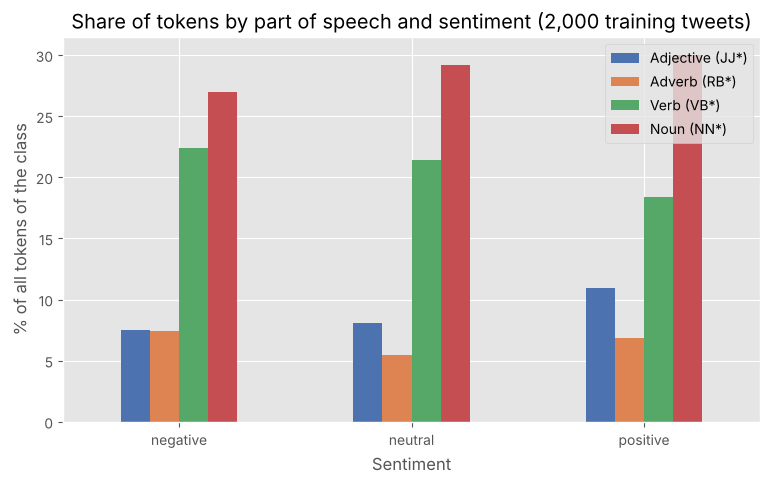

In [102]:
pos_share.T.plot(kind='bar', figsize=(9,5), color=['#4c72b0', '#dd8452', '#55a868', '#c44e52'])
plt.title("Share of tokens by part of speech and sentiment (2,000 training tweets)")
plt.ylabel("% of all tokens of the class")
plt.xlabel("Sentiment")
plt.xticks(rotation=0)
plt.savefig('screenshots/10_pos_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

In [103]:
top_adjectives = pd.DataFrame({
    label: [f"{w} ({c})" for w, c in adjectives[label].most_common(10)]
    for label in ['negative', 'positive']
}, index=range(1, 11))

top_adjectives

,negative,positive
1,i (81),great (29)
2,late (55),best (15)
3,worst (41),i (13)
4,more (32),much (13)
5,last (32),awesome (11)
6,flightled (31),good (10)
7,united (28),nice (8)
8,u (28),helpful (7)
9,due (26),excellent (7)
10,other (25),last (7)


#### What I observe

- **Positive tweets contain the largest share of adjectives** (10.9% vs 7.5% in negative and 8.1% in neutral tweets). Customers praise with adjectives: great, best, awesome, good, nice, helpful, excellent.
- **Negative tweets contain the largest share of adverbs** (7.4% vs 5.4% neutral) and of verbs (22.4%). The adverb group includes `not`, `no` and `never`, so negation is typical for complaints; the verbs describe what went wrong (cancelled, waiting, delayed).
- **Neutral tweets have the fewest adverbs** (5.4%): they are mostly questions and requests without emotional words.
- **Warning:** the sample is only 2,000 tweets, and tagger mistakes show up in the adjective list: `i`, `u` and `united` are counted as adjectives in the negative class because lower-cased text confuses the tagger. The true negative adjectives are `late`, `worst`, `due`, `flightled`.

## 7.5 POS-filtered features

In [104]:
def pos_filter(text):
    """Keep only adjectives, adverbs and verbs (and the negation words)."""
    tagged = pos_tag_fast(text.split())
    kept = [w for w, tag in tagged if tag.startswith(('JJ', 'RB', 'VB')) or w in keep_words]
    return " ".join(kept)

start = time.perf_counter()
X_train_pos = X_train_clean.apply(pos_filter)
X_test_pos  = X_test_clean.apply(pos_filter)
print(f"Tagged {len(X_train_pos) + len(X_test_pos)} tweets in {time.perf_counter() - start:.1f} s")

pd.DataFrame({'Cleaned tweet': X_train_clean.head(4).values, 'POS-filtered (JJ, RB, VB, negations)': X_train_pos.head(4).values})

Tagged 14427 tweets in 6.9 s


,Cleaned tweet,"POS-filtered (JJ, RB, VB, negations)"
0,no not boarding order someone boarded with service animal which a member of my party was allergic to and because the flight was,no not boarding boarded was allergic was
1,sucks delayed my mom flight x cancelled flightled it delayed her flight again today all for mech issues she had sleep in airport,delayed cancelled flightled delayed again had sleep
2,rt our fleet on fleek,rt
3,when i read it say in some cases can you please define this for me when for example would it not be the case,read say please define not be


In [105]:
pos_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2)),
    ('clf',   LogisticRegression(max_iter=1000, class_weight='balanced'))
])

start = time.perf_counter()
pos_pipeline.fit(X_train_pos, y_train)
pos_time = time.perf_counter() - start

pos_pred = pos_pipeline.predict(X_test_pos)

pos_row = result_row('POS-filtered (JJ/RB/VB + negations) TF-IDF (1,2)', 'Logistic Regression', pos_pred, pos_time)

results_with_pos = pd.concat([results_table, pd.DataFrame({'(g)': pos_row}).T])
for col in ['Accuracy','Macro-F1','Precision (negative)','Recall (positive)','Training time (s)']:
    results_with_pos[col] = results_with_pos[col].astype(float)

results_with_pos.style.format({
    'Accuracy': '{:.4f}', 'Macro-F1': '{:.4f}', 'Precision (negative)': '{:.4f}',
    'Recall (positive)': '{:.4f}', 'Training time (s)': '{:.2f}'
}).highlight_max(subset=['Macro-F1'], color='lightgreen')

,Features,Classifier,Accuracy,Macro-F1,Precision (negative),Recall (positive),Training time (s)
(a),Bag-of-Words,Multinomial Naive Bayes,0.7699,0.6709,0.7798,0.5852,0.24
(b),Bag-of-Words,Logistic Regression,0.7678,0.7247,0.8955,0.7598,0.76
(c),TF-IDF unigrams,Logistic Regression,0.7741,0.7319,0.8881,0.7686,0.43
(d),TF-IDF unigrams+bigrams,Logistic Regression,0.7997,0.7534,0.8925,0.7555,0.80
(e),"Word2Vec (CBoW, averaged)",Logistic Regression,0.7013,0.6569,0.8780,0.7293,3.91
(f),TF-IDF unigrams+bigrams,Linear SVM,0.8035,0.7456,0.8624,0.7140,0.64
(g),"POS-filtered (JJ/RB/VB + negations) TF-IDF (1,2)",Logistic Regression,0.7003,0.6377,0.8705,0.6070,0.42


In [106]:
print("Full-text pipeline (d)   : macro-F1 =", round(results_table.loc['(d)', 'Macro-F1'], 4), " vocabulary =", len(baseline.named_steps['tfidf'].vocabulary_))
print("POS-filtered pipeline (g): macro-F1 =", round(pos_row['Macro-F1'], 4), " vocabulary =", len(pos_pipeline.named_steps['tfidf'].vocabulary_))

Full-text pipeline (d)   : macro-F1 = 0.7534  vocabulary = 22825
POS-filtered pipeline (g): macro-F1 = 0.6377  vocabulary = 8601


#### Did POS filtering help?

**It hurt.** Macro-F1 fell from **0.753** (full text) to **0.638** (only adjectives, adverbs, verbs and negations), and accuracy from 0.800 to 0.700. The vocabulary shrank from 22,825 to 8,601 features.

Why:
- The strongest complaint clues are often **nouns**: `hold`, `hours`, `luggage`, `bag`, `service`, `phone`, `gate` and phrases like `customer service`. The filter deletes them.
- Words such as `thanks` are not always tagged as an adjective, adverb or verb, so positive clues are lost.
- The tagger makes mistakes on lower-cased tweets (see 7.3), so useful words are removed and others kept by accident.
- Removing words breaks the bigrams (`on hold` is no longer a pair).

So a plain TF-IDF pipeline on all words is better for this dataset. POS information could still help if it was used to *add* features instead of deleting words.

# Task 8: Build the NLP Project and Deploy on Streamlit

**Objective:** Package the cleaning code, the heuristic and the trained model into a Streamlit app and prepare it for deployment on Streamlit Community Cloud.

**Expected output:** `nlp_utils.py`, `app.py`, `requirements.txt`, a robustness test of the app with 7 inputs, and a reflection. The live URL, GitHub repository and screenshots are added outside the notebook.

## 8.1 Plan the app

```text
┌─────────────────────────┬──────────────────────────────────────────────────┐
│ SIDEBAR                 │  ✈️ Airline Tweet Sentiment Analyzer              │
│                         │                                                  │
│ About this project      │  Type a tweet about an airline ...               │
│ • what the app does     │                                                  │
│ • Kaggle dataset link   │  [😊 Positive] [😠 Negative] [😐 Neutral]  <- examples
│ • the 3 approaches      │  ┌────────────────────────────────────────────┐  │
│ • note on class         │  │ text box (st.text_area)                    │  │
│   imbalance             │  └────────────────────────────────────────────┘  │
│                         │  Approach: (•) Heuristic ( ) VADER ( ) ML model  │
│                         │  [ Predict ]                                     │
│                         │  ───────────── after pressing Predict ───────── │
│                         │  1. Cleaned text                                 │
│                         │  2. Coloured result (green / orange / red)       │
│                         │  3. Bar chart of class probabilities (ML only)   │
│                         │  ▸ Expander: POS tags of the tweet               │
└─────────────────────────┴──────────────────────────────────────────────────┘
```

**What the user sees after pressing Predict:** the cleaned version of the tweet, a coloured message with the predicted sentiment (green = positive, orange = neutral, red = negative), a small line with the score or confidence, for the ML model a bar chart of the three class probabilities, and an expander with the POS tags. For empty input, an emoji-only text or a link-only text, a friendly warning is shown instead of a crash.

## 8.2 Project structure

```text
airline-tweet-sentiment/
├── app.py                    <- Streamlit app
├── nlp_utils.py              <- clean_text, heuristic lexicon, heuristic_sentiment (shared with this notebook)
├── sentiment_model.joblib    <- saved TF-IDF + Logistic Regression pipeline (Task 6.7)
├── requirements.txt          <- pinned versions (Task 8.6)
├── README.md
├── NLP_PR1.ipynb / NLP_PR1.html
└── screenshots/              <- analysis plots (saved by this notebook) + app screenshots
```
The raw dataset is **not** copied into the repository; the README links to the Kaggle page instead.

The next cell writes `nlp_utils.py`. It contains the same `clean_text`, lexicon and `heuristic_sentiment` that were developed in Tasks 2 and 3.2, so the notebook and the app use identical code.

In [107]:
%%writefile nlp_utils.py
"""Shared helpers for the Airline Tweet Sentiment Analyzer.

The notebook (NLP_PR1.ipynb) and the Streamlit app (app.py) both import this file,
so cleaning and the heuristic classifier behave exactly the same in both places.
"""
import html
import re

MAX_CHARS = 500   # longer input is truncated in the app


def clean_text(text):

    # Convert to lowercase
    text = str(text).lower()

    # Decode HTML entities (&amp; -> &) and normalise curly apostrophes
    text = html.unescape(text)
    text = text.replace("’", "'").replace("‘", "'")

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove @mentions
    text = re.sub(r'@\w+', ' ', text)

    # Remove hashtag symbol but keep the word
    text = re.sub(r'#(\w+)', r'\1', text)

    # Expand negative contractions so the negation survives punctuation removal
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bcannot\b", "can not", text)
    text = re.sub(r"n't\b", " not", text)

    # Remove other contractions ('s, 'll, 're, 've, 'd, 'm)
    text = re.sub(r"'(?:s|ll|re|ve|d|m)\b", "", text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation, emoji and symbols
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Airline-specific sentiment lexicon
positive_words = {
    "thanks", "thank", "thx", "great", "love", "loved", "good", "best",
    "awesome", "amazing", "appreciate", "appreciated", "helpful", "nice",
    "excellent", "fantastic", "wonderful", "perfect", "friendly", "kind",
    "smooth", "comfortable", "easy", "happy", "glad", "enjoy", "enjoyed",
    "impressed", "outstanding", "superb", "professional", "pleasant",
    "brilliant", "favorite", "fabulous", "grateful"
}

negative_words = {
    "cancelled", "canceled", "cancel", "flightled", "delayed", "delay",
    "delays", "late", "lost", "worst", "rude", "terrible", "awful",
    "horrible", "bad", "worse", "hate", "hold", "waiting", "stuck",
    "broken", "disappointed", "disappointing", "unacceptable", "ridiculous",
    "mess", "nightmare", "fail", "failed", "refund", "missed", "damaged",
    "stranded", "unhappy", "angry", "frustrated", "frustrating", "useless",
    "hours", "hrs"
}

negation_words = {"not", "no", "never"}


def heuristic_score(text):

    words = clean_text(text).split()

    score = 0

    for i, word in enumerate(words):

        if word in positive_words:
            polarity = 1
        elif word in negative_words:
            polarity = -1
        else:
            continue

        # flip the polarity if one of the previous two words is a negation
        if any(w in negation_words for w in words[max(0, i-2):i]):
            polarity = -polarity

        score += polarity

    return score


def heuristic_sentiment(text):

    score = heuristic_score(text)

    if score > 0:
        return "positive"

    elif score < 0:
        return "negative"

    else:
        return "neutral"

Overwriting nlp_utils.py


In [108]:
# Proof that the shared file behaves exactly like the notebook functions
import importlib
import nlp_utils
importlib.reload(nlp_utils)

same_cleaning  = (df['text'].apply(nlp_utils.clean_text) == df['clean_text']).all()
same_heuristic = (X_test.apply(nlp_utils.heuristic_sentiment) == heuristic_predictions).all()

print("clean_text identical on all tweets      :", same_cleaning)
print("heuristic identical on all test tweets  :", same_heuristic)
print("Lexicon sizes in nlp_utils              :", len(nlp_utils.positive_words), "positive /", len(nlp_utils.negative_words), "negative")

clean_text identical on all tweets      : True
heuristic identical on all test tweets  : True
Lexicon sizes in nlp_utils              : 36 positive / 40 negative


## 8.3 Write app.py

The app uses `st.set_page_config`, a `st.text_area`, three example buttons, a `st.radio` approach selector, a Predict button, `@st.cache_resource` for loading the model once, coloured results (`st.success` / `st.warning` / `st.error`), `st.bar_chart` for the class probabilities and an `st.expander` with the POS tags.

In [109]:
%%writefile app.py
"""Airline Tweet Sentiment Analyzer - Streamlit app (Task 8)."""
from pathlib import Path

import joblib
import nltk
import pandas as pd
import streamlit as st
from nltk.sentiment import SentimentIntensityAnalyzer

from nlp_utils import MAX_CHARS, clean_text, heuristic_score, heuristic_sentiment

st.set_page_config(page_title="Airline Tweet Sentiment Analyzer", page_icon="✈️")

MODEL_PATH = Path(__file__).parent / "sentiment_model.joblib"

APPROACHES = [
    "Heuristic (rules)",
    "VADER (ready-made)",
    "ML model (TF-IDF + Logistic Regression)",
]

EXAMPLES = {
    "😊 Positive example": "@united thanks for the great service, the crew was awesome!",
    "😠 Negative example": "@delta my flight was cancelled and I am not happy with the delay. Worst airline!!!",
    "😐 Neutral example": "@SouthwestAir what is the baggage allowance for international flights?",
}


# ---------------------------------------------------------------- start-up helpers
@st.cache_resource
def setup_nltk():
    """Download the NLTK data the app needs; never crash if the download fails."""
    for package in ("vader_lexicon", "averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"):
        try:
            nltk.download(package, quiet=True)
        except Exception:
            pass
    return True


@st.cache_resource
def load_model():
    """Load the saved scikit-learn pipeline (vectoriser + classifier) only once."""
    return joblib.load(MODEL_PATH)


@st.cache_resource
def load_vader():
    return SentimentIntensityAnalyzer()


def vader_label(compound):
    if compound >= 0.05:
        return "positive"
    if compound <= -0.05:
        return "negative"
    return "neutral"


def show_label(label):
    """Coloured result message."""
    if label == "positive":
        st.success("Predicted sentiment: POSITIVE 😊")
    elif label == "negative":
        st.error("Predicted sentiment: NEGATIVE 😠")
    else:
        st.warning("Predicted sentiment: NEUTRAL 😐")


def set_example(text):
    st.session_state["tweet"] = text


setup_nltk()

# ---------------------------------------------------------------- layout
st.title("✈️ Airline Tweet Sentiment Analyzer")
st.write("Type a tweet about an airline and see whether it is **positive**, **neutral** or **negative**.")

with st.sidebar:
    st.header("About this project")
    st.write(
        "This app is the final step of an NLP practical: raw tweets are cleaned with RegEx, "
        "converted to features and classified with three different approaches."
    )
    st.markdown(
        "**Dataset:** [Twitter US Airline Sentiment (Kaggle)]"
        "(https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) - about 14,600 real tweets."
    )
    st.markdown(
        "**Approaches**\n"
        "- *Heuristic*: my own airline word lists + negation rule\n"
        "- *VADER*: ready-made sentiment engine\n"
        "- *ML model*: TF-IDF (1-2 grams) + Logistic Regression trained on the tweets"
    )
    st.caption("The dataset is imbalanced (about 63% negative), so the neutral class is the hardest to predict.")

if "tweet" not in st.session_state:
    st.session_state["tweet"] = ""

st.write("Try an example:")
columns = st.columns(3)
for column, (label, example_text) in zip(columns, EXAMPLES.items()):
    column.button(label, on_click=set_example, args=(example_text,))

st.text_area("Tweet text", key="tweet", height=130, placeholder="Type or paste a tweet here ...")

approach = st.radio("Choose an approach", APPROACHES, horizontal=True)

predict = st.button("Predict", type="primary")

# ---------------------------------------------------------------- prediction
if predict:
    raw = st.session_state["tweet"]

    # 1. empty input
    if not raw or not raw.strip():
        st.warning("Please type a tweet or click one of the examples first.")
        st.stop()

    # 2. very long input
    if len(raw) > MAX_CHARS:
        raw = raw[:MAX_CHARS]
        st.info(f"The text was longer than {MAX_CHARS} characters, so only the first {MAX_CHARS} are analysed.")

    # 3. cleaned text (same function as in the notebook)
    cleaned = clean_text(raw)
    st.subheader("1. Cleaned text")

    if not cleaned:
        st.warning(
            "Nothing is left after cleaning. The text contains only emojis, symbols, numbers or a link. "
            "Please write some words."
        )
        st.stop()

    st.code(cleaned, language=None)

    # 4. prediction
    st.subheader("2. Prediction")
    probabilities = None

    if approach == APPROACHES[0]:
        score = heuristic_score(raw)
        label = heuristic_sentiment(raw)
        details = f"Lexicon score = {score} (positive words minus negative words, negation handled)"

    elif approach == APPROACHES[1]:
        try:
            scores = load_vader().polarity_scores(raw)      # VADER works best on the raw text
        except LookupError:
            st.error("The VADER lexicon could not be downloaded. Please choose another approach.")
            st.stop()
        label = vader_label(scores["compound"])
        details = f"VADER compound score = {scores['compound']:.3f}  (neg {scores['neg']}, neu {scores['neu']}, pos {scores['pos']})"

    else:
        try:
            model = load_model()
        except Exception as error:
            st.error(f"The model file could not be loaded ({error}). Check the scikit-learn version in requirements.txt.")
            st.stop()
        proba = model.predict_proba([cleaned])[0]
        label = model.classes_[proba.argmax()]
        probabilities = pd.Series(proba, index=model.classes_, name="probability")
        details = f"Confidence = {proba.max():.1%}"

    show_label(label)
    st.caption(details)

    if probabilities is not None:
        st.subheader("3. Class probabilities")
        st.bar_chart(probabilities)

    # 5. POS tags
    with st.expander("Show the POS tags of this tweet"):
        try:
            tags = nltk.pos_tag(cleaned.split())
            st.dataframe(pd.DataFrame(tags, columns=["Word", "POS tag"]), hide_index=True)
            st.caption("Tagged with NLTK's averaged-perceptron tagger. It was trained on news text, so tweets may contain mistakes.")
        except LookupError:
            st.info("The POS tagger data is not available in this environment.")

Overwriting app.py


## 8.4 Robustness

The app handles: **empty input** (warning), **very long input** (cut to 500 characters with a message), **text that is empty after cleaning** (e.g. only emojis or a link) and **missing NLTK data** (downloaded at start-up inside `try/except` with `quiet=True`). The cell below runs the real `app.py` headlessly with Streamlit's `AppTest` and reports what the user would see.

In [110]:
import logging
logging.getLogger("streamlit").setLevel(logging.ERROR)   # hide harmless "missing ScriptRunContext" messages in bare mode

from streamlit.testing.v1 import AppTest

ML_APPROACH = "ML model (TF-IDF + Logistic Regression)"

test_inputs = [
    ("Empty string",              "",                                                                   ML_APPROACH),
    ("Spaces only",               "     ",                                                              ML_APPROACH),
    ("Only emojis",               "😡😡😡✈️💔",                                                         ML_APPROACH),
    ("URL only",                  "https://t.co/abc123XYZ",                                             ML_APPROACH),
    ("ALL-CAPS angry tweet",      "THIS IS THE WORST AIRLINE EVER!!! 3 HOURS LATE AND NOBODY CARES",    ML_APPROACH),
    ("Negation",                  "I am not happy with the delay",                                      ML_APPROACH),
    ("Negation (heuristic)",      "I am not happy with the delay",                                      "Heuristic (rules)"),
    ("Positive (VADER)",          "Thanks for the great service, the crew was awesome!",                "VADER (ready-made)"),
    ("Very long input (700 chars)", "the flight was delayed again " * 25,                               ML_APPROACH),
]

from IPython.utils.capture import capture_output

report = []
cap = capture_output(stdout=True, stderr=True)   # hides Streamlit's harmless bare-mode log lines
cap.__enter__()
for name, text, approach_name in test_inputs:
    at = AppTest.from_file(os.path.abspath("app.py"), default_timeout=60).run()
    at.text_area[0].set_value(text)
    at.radio[0].set_value(approach_name)
    [b for b in at.button if b.label == "Predict"][0].click()
    at.run()

    outcome = []
    for kind in ["warning", "info", "success", "error"]:
        for el in getattr(at, kind):
            outcome.append(f"{kind}: {el.value}")
    report.append({
        'Test input': name,
        'Approach': approach_name.split(' (')[0],
        'App crashed?': len(at.exception) > 0,
        'What the user sees': " | ".join(outcome)
    })

cap.__exit__(None, None, None)

pd.DataFrame(report)

2026-11-06 08:02:39.522 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,Test input,Approach,App crashed?,What the user sees
0,Empty string,ML model,False,warning: Please type a tweet or click one of the examples first.
1,Spaces only,ML model,False,warning: Please type a tweet or click one of the examples first.
2,Only emojis,ML model,False,"warning: Nothing is left after cleaning. The text contains only emojis, symbols, numbers or a link. Please write some words."
3,URL only,ML model,False,"warning: Nothing is left after cleaning. The text contains only emojis, symbols, numbers or a link. Please write some words."
4,ALL-CAPS angry tweet,ML model,False,error: Predicted sentiment: NEGATIVE 😠
5,Negation,ML model,False,error: Predicted sentiment: NEGATIVE 😠
6,Negation (heuristic),Heuristic,False,error: Predicted sentiment: NEGATIVE 😠
7,Positive (VADER),VADER,False,success: Predicted sentiment: POSITIVE 😊
8,Very long input (700 chars),ML model,False,"info: The text was longer than 500 characters, so only the first 500 are analysed. | error: Predicted sentiment: NEGATIVE 😠"


- Nine inputs (6 required kinds: empty, only emojis, all-caps angry tweet, negation, URL-only and very long text) never crash the app. Empty, emoji-only and URL-only input show a warning, long input is truncated with an information message, and real tweets show a coloured result.

## 8.5 Run locally

Run the app from the project folder:

```bash
streamlit run app.py
```

Then take these five screenshots and save them in the `screenshots/` folder (use the names below):

1. `app_01_start_screen.png` – the start screen with the examples and the approach selector
2. `app_02_positive_prediction.png` – the positive example with the ML model
3. `app_03_negative_prediction.png` – the negative example
4. `app_04_probability_chart.png` – the probability bar chart
5. `app_05_pos_expander.png` – the POS-tag expander opened

The analysis plots (EDA, confusion matrices, results chart, PCA, POS chart) were already saved by this notebook in `screenshots/`.

## 8.6 requirements.txt

In [111]:
from importlib.metadata import version

needed_packages = ['streamlit', 'scikit-learn', 'nltk', 'pandas', 'numpy', 'joblib']

with open('requirements.txt', 'w') as f:
    for package in needed_packages:
        f.write(f"{package}=={version(package)}\n")

print(open('requirements.txt').read())
print("Model was trained with scikit-learn", sklearn.__version__)

streamlit==1.66.1
scikit-learn==1.9.1
nltk==3.10.4
pandas==3.0.6
numpy==2.5.4
joblib==1.6.0

Model was trained with scikit-learn 1.9.1


- Only the libraries that the **app** needs are listed (no gensim, matplotlib or seaborn), each pinned to the version installed in this environment, because the `.joblib` model must be loaded with the same scikit-learn version that saved it. This version is also stated in the README.

## 8.7 Deploy on Streamlit Community Cloud

Steps (done outside the notebook):

1. Create a **public** GitHub repository and push the files from 8.2 (at least three meaningful commits).
2. Open **share.streamlit.io**, sign in with GitHub and choose **New app**.
3. Select the repository, the branch and `app.py`, then click **Deploy**.
4. Wait for the build. If it fails, read the log: usually `requirements.txt` has a wrong version or an NLTK resource is missing.
5. Open the public URL, test **3 predictions** (include a negation) and paste the URL at the **top of README.md** and in the video.

```bash
git init
git add NLP_PR1.ipynb NLP_PR1.html nlp_utils.py
git commit -m "Add RegEx cleaning pipeline and EDA"
git add sentiment_model.joblib screenshots
git commit -m "Add BoW, TF-IDF, N-gram and Word2Vec experiments with comparison table"
git add app.py requirements.txt README.md
git commit -m "Add Streamlit app, requirements and deployment"
git branch -M main
git remote add origin https://github.com/<your-username>/<repo-name>.git
git push -u origin main
```

## 8.8 Reflection

### What I learned

**(a) Which pipeline stage had the biggest effect?** The biggest jump came from **using labelled domain data at all** (Task 4-6): macro-F1 went from 0.52-0.57 (VADER, heuristic) to 0.73-0.75 (TF-IDF models). Inside the ML pipeline, the **cleaning rule that keeps negations** (expanding `didn't` → `did not`) and the **bigram features** (+0.02) mattered most, while `class_weight='balanced'` raised the macro-F1 from 0.724 to 0.753 by improving recall of the small classes. Deleting words (POS filtering) lowered the score a lot.

**(b) Which approach did I deploy and why?** The **TF-IDF (1,2) + Logistic Regression** pipeline is the default ML option in the app: best macro-F1 (0.753), gives probabilities, trains in about a second and is easy to explain. The heuristic and VADER are included as selectable options so that users can compare the three approaches on the same tweet.

**(c) One weakness of my app that a user could notice.** The model confuses the **neutral** class with the others, and it cannot understand **sarcasm**: "awesome service... NOT" or "love how you lose my bag" may be predicted as positive. Short "thanks" tweets are also always predicted positive, and emojis are deleted by the cleaning, so a tweet with only an emoji cannot be analysed.

**(d) One improvement that needs topics beyond this practical.** A **Transformer-based model (for example fine-tuning BERT)** reads the whole sentence with context, so it can understand sarcasm and negation scope much better than bag-of-words features. (Named only, not implemented.)